# Project 1 — LoS/NLoS Classification from Channel State Information (CSI)

**Task:** decide for every CSI sample whether the vehicle is in **line-of-sight (LoS = 0)** or **non-line-of-sight (NLoS = 1)** of the remote radio unit (RRU).

| Family | Methods in this notebook |
|---|---|
| Machine learning (ML) | Logistic Regression, Support Vector Machine (RBF kernel), K-Nearest Neighbours, Random Forest, Gradient Boosting |
| Artificial neural networks (ANN) | MLP, 1-D CNN, 2-D CNN, residual 1-D CNN (ResNet), CNN + BiGRU, Transformer, CIR-CNN, two-branch fusion CNN |

**Pipeline**
1. Read `train_dl.pt` / `valid_dl.pt` → complex CSI (4 antennas × 1632 subcarriers) and labels.
2. Pre-processing → three input formats: amplitude image |H| (4 × 408), channel impulse response (4 × 128 taps) and 46 physical features.
3. ML: comparison of the input formats, hyper-parameter grid for every model, final models.
4. ANN: eight architectures, then a configuration study (hidden activation, output layer / loss, optimizer, learning rate, batch size, input normalization).
5. Evaluation: accuracy, precision, recall, F1, ROC-AUC, confusion matrices, efficiency (training time, inference time, model size).
6. Extra studies: robustness on an emulated unreliable network (noisy CSI, lost CSI packets) and generalization to positions never seen in training.

## 0. Imports and settings

In [1]:
import os
import io
import copy
import json
import time
import pickle
import random
import warnings
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
import seaborn as sn

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

In [3]:
import sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report, log_loss)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

Fixed random seeds make every run repeatable. The networks run on the GPU when one is available, otherwise on the CPU.
Every network is trained for at most `MAX_EPOCHS` epochs with **early stopping**: training stops when the validation
loss has not improved for `PATIENCE` epochs, and the weights of the best validation epoch (the best checkpoint) are
restored before the network is evaluated.

In [4]:
SEED = 0
MAX_EPOCHS = 25
PATIENCE = 5


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True

PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
COLORS = {'LoS': PALETTE[0], 'NLoS': PALETTE[1], 'ML': PALETTE[1], 'ANN': PALETTE[0]}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9.5, 'axes.prop_cycle': plt.cycler(color=PALETTE),
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.edgecolor': '#c3c2b7',
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'axes.titlesize': 10.5, 'legend.frameon': False, 'axes.axisbelow': True})


def log_axis(ax, axis='x'):
    """Log scale with plain tick labels (0.1, 0.2, 0.5, 1, 2, 5, ...)."""
    target = ax.xaxis if axis == 'x' else ax.yaxis
    (ax.set_xscale if axis == 'x' else ax.set_yscale)('log')
    target.set_major_locator(LogLocator(subs=(1, 2, 5)))
    target.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    target.set_minor_formatter(NullFormatter())

print('device :', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
print('torch', torch.__version__, '| scikit-learn', sklearn.__version__, '| numpy', np.__version__)

device : cuda NVIDIA GeForce RTX 5060 Laptop GPU
torch 2.14.0+cu130 | scikit-learn 1.7.2 | numpy 2.2.6


## 1. Read the dataset
`train_dl.pt` and `valid_dl.pt` store PyTorch `DataLoader` objects that hold one `TensorDataset`:
- CSI: complex tensor `(N, 1, 4, 1632)` — 4 RRU antennas × 1632 subcarriers;
- label: `(N, 3)` — `x`, `y` (metres, relative to the RRU) and the LoS indicator (`0` = LoS, `1` = NLoS).

Column 2 is the class label of this task; `x`, `y` are only used for maps and for the split by position in Section 8.
`weights_only=False` is required with PyTorch ≥ 2.6 because the files contain pickled `DataLoader` objects.

In [5]:
train_dl = torch.load('Dataset/train_dl.pt', weights_only=False)
valid_dl = torch.load('Dataset/valid_dl.pt', weights_only=False)
train_CSI, train_label = train_dl.dataset[:]
valid_CSI, valid_label = valid_dl.dataset[:]
train_CSI, valid_CSI = train_CSI[:, 0], valid_CSI[:, 0]          # (N, 4, 1632) complex64
del train_dl, valid_dl

y_train = train_label[:, 2].long().numpy()                       # 0 = LoS, 1 = NLoS
y_valid = valid_label[:, 2].long().numpy()
pos_train = train_label[:, :2].numpy()
pos_valid = valid_label[:, :2].numpy()
CLASSES = ['LoS', 'NLoS']

print('CSI      :', tuple(train_CSI.shape), train_CSI.dtype)
for name, y, pos in [('train', y_train, pos_train), ('valid', y_valid, pos_valid)]:
    print(f'{name:9s}: {len(y):5d} samples | LoS {np.sum(y == 0):5d} | NLoS {np.sum(y == 1):4d} '
          f'({100 * y.mean():.1f} %) | {len(np.unique(pos, axis=0))} positions')
print('always predicting LoS would give %.1f %% validation accuracy' % (100 * np.mean(y_valid == 0)))

CSI      : (15000, 4, 1632) torch.complex64
train    : 15000 samples | LoS 12340 | NLoS 2660 (17.7 %) | 476 positions
valid    :  5000 samples | LoS  4064 | NLoS  936 (18.7 %) | 476 positions
always predicting LoS would give 81.3 % validation accuracy


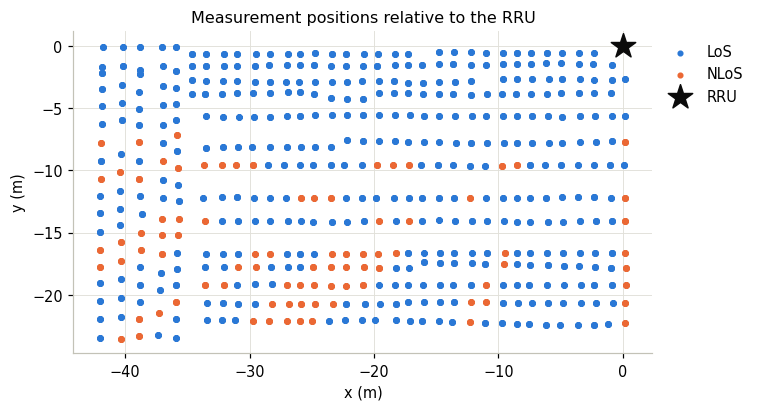

In [6]:
# Figure: measurement positions
fig, ax = plt.subplots(figsize=(8, 3.8))
for c, name in enumerate(CLASSES):
    m = y_train == c
    ax.scatter(pos_train[m, 0], pos_train[m, 1], s=9, color=COLORS[name], label=name)
ax.scatter(0, 0, marker='*', s=280, color='#0b0b0b', label='RRU')
ax.set(xlabel='x (m)', ylabel='y (m)', title='Measurement positions relative to the RRU')
ax.set_aspect('equal')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

## 2. Data pre-processing
The complex CSI $H_{a,k}$ (antenna $a$, subcarrier $k$) is turned into **three input formats**:

1. **Amplitude image** $|H_{a,k}|$. The phase is not used directly: it contains random offsets of the receiver
   (timing, oscillator) that change from one measurement to the next. Groups of 4 neighbouring subcarriers are
   averaged (1632 → 408), which keeps the shape of the frequency response, reduces noise and makes training 4×
   cheaper. The values are min-max normalized to [0, 1] with the **training** minimum and maximum:
   $x_{norm} = (x - x_{min}) / (x_{max} - x_{min})$. Two alternatives are tested in Section 6.2: dB scale
   ($20\log_{10}(1+|H|)$, then min-max) and per-sample scaling ($|H| / \max |H|$ of the sample).
2. **Channel impulse response (CIR)** $|h_a[\tau]| = |\mathrm{IFFT}_k(H_{a,k})|$: the CSI in the delay domain.
   The first 128 taps contain 99.4 % of the energy and are kept (4 × 128), scaled by the training maximum.
   A LoS channel has one dominant early path; NLoS energy is spread over many delayed paths.
3. **46 physical features** (10 per antenna + 6 inter-antenna correlations) known from the LoS/NLoS identification
   literature: received power (dB), frequency selectivity (std of |H| in dB), Rician K-factor (moment estimate
   $K = \sqrt{1-\gamma}/(1-\sqrt{1-\gamma})$ with $\gamma = \mathrm{Var}(|H|^2)/E[|H|^2]^2$), kurtosis of |H|,
   delay of the strongest tap, energy ratio of the strongest tap, mean excess delay, RMS delay spread, delay and
   relative power of the first path (first tap within 10 dB of the peak), and the correlation of |H| between antenna pairs.

The same function `preprocess` is used for the training data, the validation data and for the corrupted copies of
the validation CSI in Section 7, so every model always sees inputs computed in exactly the same way.

In [7]:
POOL = 4          # neighbouring subcarriers averaged together (1632 -> 408)
N_TAPS = 128      # CIR taps kept
PER_ANTENNA = ['power_dB', 'freq_std_dB', 'K_factor_dB', 'kurtosis', 'peak_tap', 'peak_ratio_dB',
               'mean_delay', 'rms_delay', 'first_path_tap', 'first_path_dB']
PHYS_NAMES = ([f'{n} (ant {a + 1})' for n in PER_ANTENNA for a in range(4)] +
              [f'corr (ant {i + 1},{j + 1})' for i in range(4) for j in range(i + 1, 4)])
N_PHYS = len(PHYS_NAMES)


def physical_features(amp, cir):
    """46 hand-crafted features from |H| (N, 4, 1632) and |CIR| (N, 4, N_TAPS)."""
    eps = 1e-12
    p = amp ** 2
    mean_p = p.mean(-1)
    power_db = 10 * torch.log10(mean_p + eps)
    freq_std_db = (20 * torch.log10(amp + 1e-3)).std(-1)
    gamma = p.var(-1) / (mean_p ** 2 + eps)
    s = torch.sqrt(torch.clamp(1 - gamma, min=0))
    k_db = 10 * torch.log10(s / (1 - s + 1e-6) + 1e-3)
    centred = amp - amp.mean(-1, keepdim=True)
    kurtosis = (centred ** 4).mean(-1) / ((centred ** 2).mean(-1) ** 2 + eps)
    pdp = cir ** 2                                                    # power delay profile
    total = pdp.sum(-1) + eps
    tau = torch.arange(pdp.shape[-1], dtype=pdp.dtype)
    peak, peak_tap = pdp.max(-1)
    mean_delay = (pdp * tau).sum(-1) / total
    rms_delay = torch.sqrt((pdp * (tau - mean_delay[..., None]) ** 2).sum(-1) / total)
    first_tap = (pdp >= 0.1 * peak[..., None]).float().argmax(-1)    # first tap within 10 dB of the peak
    first_db = 10 * torch.log10((pdp.gather(-1, first_tap[..., None])[..., 0] + eps) / (peak + eps))
    unit = centred / (centred.norm(dim=-1, keepdim=True) + eps)
    corr = unit @ unit.transpose(1, 2)
    i, j = torch.triu_indices(4, 4, 1)
    feats = torch.cat([power_db, freq_std_db, k_db, kurtosis, peak_tap.float(), 10 * torch.log10(peak / total + eps),
                       mean_delay, rms_delay, first_tap.float(), first_db, corr[:, i, j]], dim=1)
    return torch.nan_to_num(feats)


def extract_features(H, chunk=1000):
    """complex CSI (N, 4, 1632) -> amplitude (N, 4, 408), |CIR| (N, 4, 128), physical features (N, 46)."""
    amp, cir, phys = [], [], []
    for Hc in torch.split(H, chunk):
        a = Hc.abs()
        h = torch.fft.ifft(Hc, dim=-1).abs()[..., :N_TAPS]
        amp.append(F.avg_pool1d(a, POOL))
        cir.append(h)
        phys.append(physical_features(a, h))
    return torch.cat(amp), torch.cat(cir), torch.cat(phys)


def to_db(amp):
    return 20 * torch.log10(1 + amp)


class Normalizer:
    """Scaling to [0, 1] with statistics of the training set only (no information from the validation set)."""
    def __init__(self, amp, cir):
        self.amp_min, self.amp_max = amp.min().item(), amp.max().item()
        db = to_db(amp)
        self.db_min, self.db_max = db.min().item(), db.max().item()
        self.cir_max = cir.max().item()

    def __call__(self, amp, cir):
        return {'amp': (amp - self.amp_min) / (self.amp_max - self.amp_min),
                'amp_db': (to_db(amp) - self.db_min) / (self.db_max - self.db_min),
                'amp_sample': amp / (amp.amax(dim=(1, 2), keepdim=True) + 1e-12),
                'cir': cir / self.cir_max}


def preprocess(H):
    """complex CSI -> all model inputs (normalized with the training statistics)."""
    amp, cir, phys = extract_features(H)
    return {**norm(amp, cir), 'phys': phys.numpy()}

In [8]:
t0 = time.time()
amp_raw, cir_raw, phys_raw = extract_features(train_CSI)
norm = Normalizer(amp_raw, cir_raw)                              # statistics of the training set only
train_in = {**norm(amp_raw, cir_raw), 'phys': phys_raw.numpy()}
amp_raw_v, cir_raw_v, phys_raw_v = extract_features(valid_CSI)
valid_in = {**norm(amp_raw_v, cir_raw_v), 'phys': phys_raw_v.numpy()}
RAW = {'amp': torch.cat([amp_raw, amp_raw_v]), 'cir': torch.cat([cir_raw, cir_raw_v])}   # unscaled, for Section 9
del amp_raw, cir_raw, phys_raw, amp_raw_v, cir_raw_v, phys_raw_v
print(f'pre-processing of 20,000 samples: {time.time() - t0:.1f} s')
print(f'training |H| range before scaling: [{norm.amp_min:.1f}, {norm.amp_max:.1f}]')
for k, v in train_in.items():
    print(f'{k:11s} {str(tuple(v.shape)):16s} range [{v.min():8.3f}, {v.max():8.3f}]')

pre-processing of 20,000 samples: 5.4 s
training |H| range before scaling: [1.9, 2825.0]
amp         (15000, 4, 408)  range [   0.000,    1.000]
amp_db      (15000, 4, 408)  range [   0.000,    1.000]
amp_sample  (15000, 4, 408)  range [   0.004,    1.000]
cir         (15000, 4, 128)  range [   0.000,    1.000]
phys        (15000, 46)      range [ -30.000,  123.000]


**Check: the pre-processing uses the training data only.** The scaling statistics come from `train_dl.pt`; the
validation data are transformed with the same statistics, so the scaled training data lie exactly in [0, 1] while the
validation data may fall slightly outside. The PCA and standardization steps of the ML models are fitted inside each
pipeline on the training rows only; in Section 9 all statistics are recomputed from the seen positions only.

In [9]:
n_tr = len(y_train)
assert norm.amp_min == RAW['amp'][:n_tr].min().item() and norm.amp_max == RAW['amp'][:n_tr].max().item()
assert norm.cir_max == RAW['cir'][:n_tr].max().item()
for name, inputs in [('train', train_in), ('valid', valid_in)]:
    print(f"{name}: scaled |H| in [{inputs['amp'].min():.4f}, {inputs['amp'].max():.4f}] | "
          f"scaled CIR in [{inputs['cir'].min():.4f}, {inputs['cir'].max():.4f}]")
print('all scaling statistics are computed from the 15,000 training samples only: OK')

train: scaled |H| in [0.0000, 1.0000] | scaled CIR in [0.0000, 1.0000]
valid: scaled |H| in [0.0000, 0.8550] | scaled CIR in [0.0000, 0.9812]
all scaling statistics are computed from the 15,000 training samples only: OK


The complex training CSI is needed again only for the noise / packet-loss augmentation in Section 8. It is moved to
the GPU (if there is one) so that the corrupted inputs can be computed on the fly during training.

In [10]:
train_CSI = train_CSI.to(device)
train_gpu = {k: train_in[k].to(device) for k in ['amp', 'amp_db', 'amp_sample', 'cir']}
valid_gpu = {k: valid_in[k].to(device) for k in ['amp', 'amp_db', 'amp_sample', 'cir']}

### What separates LoS from NLoS?
Example of one LoS and one NLoS sample: the LoS impulse response has one strong early path, the NLoS response is weaker and spread over more taps.

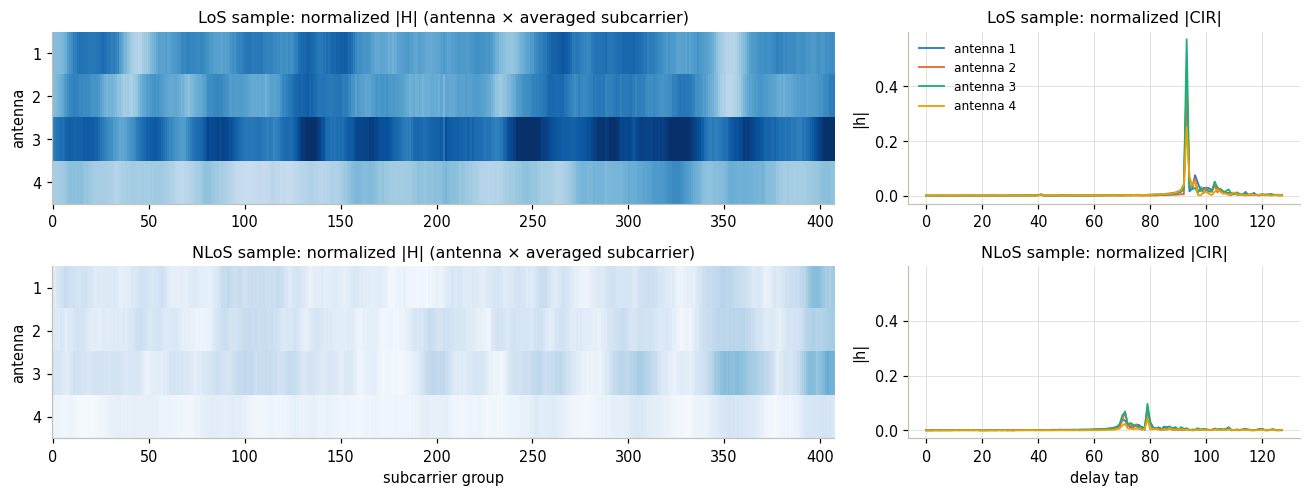

In [11]:
# Figure: example CSI amplitude and impulse response
los_i, nlos_i = np.flatnonzero(y_train == 0)[0], np.flatnonzero(y_train == 1)[0]
fig, axes = plt.subplots(2, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [2, 1]})
axes[1, 1].sharey(axes[0, 1])
vmax = float(np.percentile(train_in['amp'][[los_i, nlos_i]].numpy(), 99))
for row, (i, name) in enumerate([(los_i, 'LoS'), (nlos_i, 'NLoS')]):
    axes[row, 0].imshow(train_in['amp'][i], aspect='auto', cmap='Blues', interpolation='nearest', vmin=0, vmax=vmax)
    axes[row, 0].set(title=f'{name} sample: normalized |H| (antenna × averaged subcarrier)', ylabel='antenna',
                     yticks=range(4), yticklabels=[1, 2, 3, 4])
    axes[row, 0].grid(False)
    for a in range(4):
        axes[row, 1].plot(train_in['cir'][i, a], lw=1.2, label=f'antenna {a + 1}')
    axes[row, 1].set(title=f'{name} sample: normalized |CIR|', ylabel='|h|')
axes[1, 0].set_xlabel('subcarrier group')
axes[1, 1].set_xlabel('delay tap')
axes[0, 1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Class averages and the distribution of four physical features (mean over the 4 antennas). As expected from
propagation theory, LoS samples have a larger Rician K-factor, a smaller delay spread, a flatter spectrum and more
energy in the strongest tap.

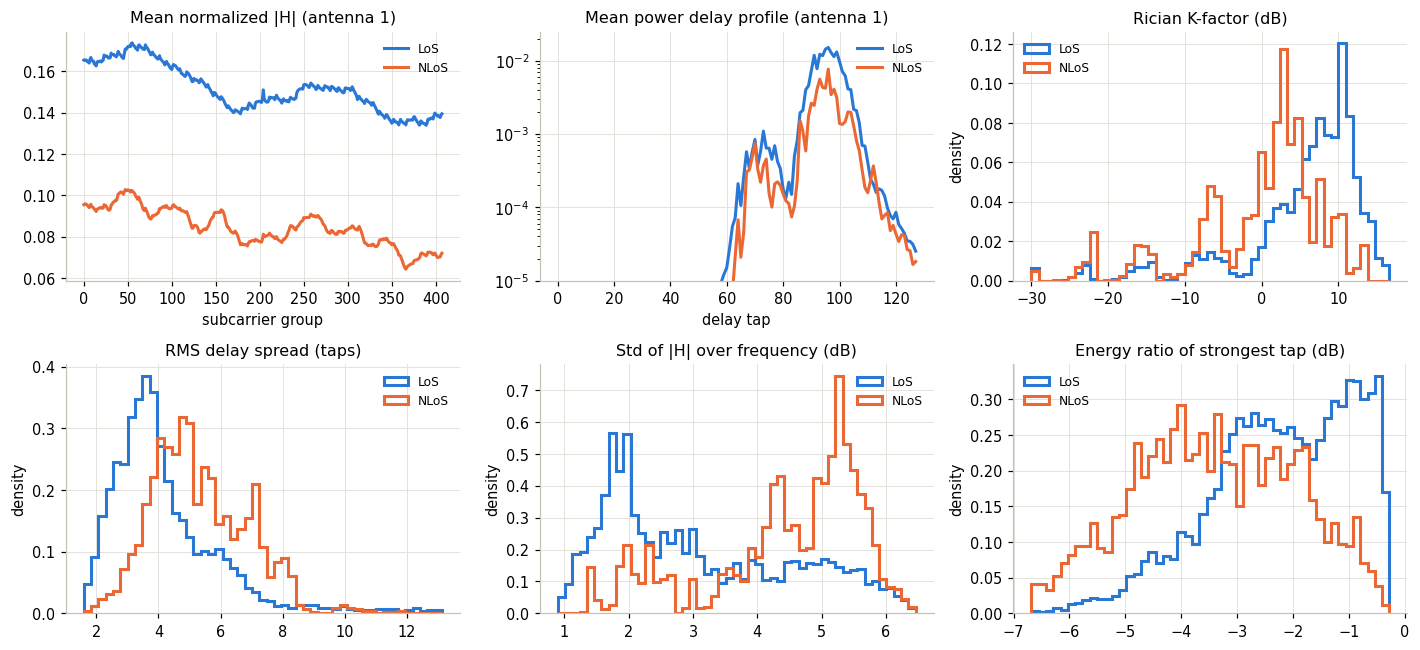

In [12]:
# Figure: LoS vs NLoS signatures
phys_df = pd.DataFrame(train_in['phys'], columns=PHYS_NAMES)


def antenna_mean(feature):
    return phys_df[[f'{feature} (ant {a + 1})' for a in range(4)]].mean(1).values


fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for c, name in enumerate(CLASSES):
    m = torch.from_numpy(y_train == c)
    axes[0, 0].plot(train_in['amp'][m, 0].mean(0), color=COLORS[name], label=name)
    axes[0, 1].semilogy(train_in['cir'][m, 0].pow(2).mean(0), color=COLORS[name], label=name)
axes[0, 0].set(title='Mean normalized |H| (antenna 1)', xlabel='subcarrier group')
axes[0, 1].set(title='Mean power delay profile (antenna 1)', xlabel='delay tap', ylim=(1e-5, None))
for ax, (feat, title) in zip([axes[0, 2], *axes[1]], [('K_factor_dB', 'Rician K-factor (dB)'),
                                                       ('rms_delay', 'RMS delay spread (taps)'),
                                                       ('freq_std_dB', 'Std of |H| over frequency (dB)'),
                                                       ('peak_ratio_dB', 'Energy ratio of strongest tap (dB)')]):
    v = antenna_mean(feat)
    bins = np.linspace(np.percentile(v, 0.5), np.percentile(v, 99.5), 50)
    for c, name in enumerate(CLASSES):
        ax.hist(v[y_train == c], bins=bins, density=True, histtype='step', lw=2, color=COLORS[name], label=name)
    ax.set(title=title, ylabel='density')
for ax in axes.flat:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Part A — Machine-learning methods
## 3. Input formats for ML and the five ML models
The ML models need a vector per sample. Four feature sets are compared:
- **Amplitude (PCA)** — the 4 × 408 amplitude image flattened (1632 values), projected on its first 100 principal components;
- **CIR (PCA)** — the 4 × 128 CIR flattened (512 values), first 100 principal components;
- **Physical** — the 46 physical features, standardized (zero mean, unit variance);
- **Physical + CIR (PCA)** — the 46 physical features and 50 CIR principal components, all standardized.

Every model is a complete scikit-learn pipeline (PCA / scaling → classifier), fitted on the training set only.

| Model | Decision function / "activation" | Output |
|---|---|---|
| Logistic Regression | $p(\text{NLoS}) = \sigma(w^\top x + b)$, sigmoid | NLoS if $p > 0.5$ |
| SVM (RBF kernel) | $f(x) = \sum_i \alpha_i y_i \exp(-\gamma\lVert x - x_i\rVert^2) + b$ | sign of $f(x)$ |
| KNN | majority vote of the $k$ nearest training fingerprints (Euclidean) | majority class |
| Random Forest | average of the votes of many decision trees (bagging, random features) | majority class |
| Gradient Boosting | sum of shallow trees fitted one after the other to the residual, sigmoid | NLoS if $p > 0.5$ |

Logistic Regression and SVM are sensitive to the scale of the inputs, so the PCA components are standardized for them;
KNN uses the raw PCA components (they keep the Euclidean distance between fingerprints); trees need no scaling.

In [13]:
FEATURE_SETS = ['Amplitude (PCA)', 'CIR (PCA)', 'Physical', 'Physical + CIR (PCA)']


def ml_matrix(inputs, feature_set):
    """The 2-D input matrix of an ML pipeline."""
    if feature_set == 'Amplitude (PCA)':
        return inputs['amp'].flatten(1).numpy()
    if feature_set == 'CIR (PCA)':
        return inputs['cir'].flatten(1).numpy()
    if feature_set == 'Physical':
        return inputs['phys']
    return np.hstack([inputs['phys'], inputs['cir'].flatten(1).numpy()])


def ml_pipeline(feature_set, model, n_pca=100, scale=True):
    if feature_set == 'Physical':
        steps = [StandardScaler()]
    elif feature_set == 'Physical + CIR (PCA)':
        steps = [ColumnTransformer([('phys', StandardScaler(), slice(0, N_PHYS)),
                                    ('cir', make_pipeline(PCA(50, random_state=SEED), StandardScaler()),
                                     slice(N_PHYS, None))])]
    else:
        steps = [PCA(n_pca, random_state=SEED)] + ([StandardScaler()] if scale else [])
    return make_pipeline(*steps, model)


ML_MODELS = {'Logistic Regression': (lambda: LogisticRegression(C=1.0, max_iter=3000), True),
             'SVM (RBF)': (lambda: SVC(C=1.0, gamma='scale'), True),
             'KNN': (lambda: KNeighborsClassifier(n_neighbors=5), False),
             'Random Forest': (lambda: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED), False),
             'Gradient Boosting': (lambda: HistGradientBoostingClassifier(random_state=SEED), False)}

Helper functions: metrics (NLoS is the positive class), training / inference time and model size (bytes of the pickled pipeline).

In [14]:
def cls_metrics(y_true, y_pred, score=None):
    m = {'accuracy': accuracy_score(y_true, y_pred),
         'precision': precision_score(y_true, y_pred, zero_division=0),
         'recall': recall_score(y_true, y_pred, zero_division=0),
         'F1': f1_score(y_true, y_pred, zero_division=0)}
    if score is not None:
        m['AUC'] = roc_auc_score(y_true, score)
    return m


def nlos_score(model, X):
    """A continuous NLoS score (probability or SVM margin) for the ROC curve."""
    return model.predict_proba(X)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X)


def fit_ml(model, X_tr, y_tr, X_te, y_te):
    start = time.time()
    model.fit(X_tr, y_tr)
    train_s = time.time() - start
    start = time.time()
    pred = model.predict(X_te)
    infer_s = time.time() - start
    score = nlos_score(model, X_te)
    return ({**cls_metrics(y_te, pred, score), 'train_s': train_s, 'infer_ms': 1000 * infer_s / len(X_te),
             'size_MB': len(pickle.dumps(model)) / 1e6}, pred, score)

### 3.1 Which input format is best for ML?
All five models with default settings on the four feature sets (validation set).

In [15]:
X_train = {fs: ml_matrix(train_in, fs) for fs in FEATURE_SETS}
X_valid = {fs: ml_matrix(valid_in, fs) for fs in FEATURE_SETS}
rows = []
for fs in FEATURE_SETS:
    for name, (make, scale) in ML_MODELS.items():
        r, _, _ = fit_ml(ml_pipeline(fs, make(), scale=scale), X_train[fs], y_train, X_valid[fs], y_valid)
        rows.append({'feature set': fs, 'model': name, **r})
feature_table = pd.DataFrame(rows)
feature_table.round(4)

,feature set,model,accuracy,precision,recall,F1,AUC,train_s,infer_ms,size_MB
0,Amplitude (PCA),Logistic Regression,0.8782,0.8277,0.4412,0.5756,0.8634,2.2097,0.0069,0.6654
1,Amplitude (PCA),SVM (RBF),0.9914,1.0000,0.9541,0.9765,0.9985,7.1610,0.3911,2.3511
2,Amplitude (PCA),KNN,0.9994,1.0000,0.9968,0.9984,1.0000,1.9554,0.1345,6.7819
3,Amplitude (PCA),Random Forest,0.9990,1.0000,0.9947,0.9973,1.0000,10.4730,0.0354,7.5973
4,Amplitude (PCA),Gradient Boosting,0.9996,1.0000,0.9979,0.9989,1.0000,5.1746,0.0086,1.2278
5,CIR (PCA),Logistic Regression,0.8386,0.7434,0.2105,0.3281,0.8300,0.2015,0.0020,0.2130
6,CIR (PCA),SVM (RBF),0.9496,0.9831,0.7436,0.8467,0.9769,3.4443,0.7365,3.1934
7,CIR (PCA),KNN,0.9806,0.9605,0.9348,0.9475,0.9940,1.7264,0.1858,6.3294
8,CIR (PCA),Random Forest,0.9822,0.9942,0.9103,0.9504,0.9983,6.1722,0.0306,17.2330
9,CIR (PCA),Gradient Boosting,0.9848,0.9909,0.9274,0.9581,0.9951,6.4409,0.0157,0.7754


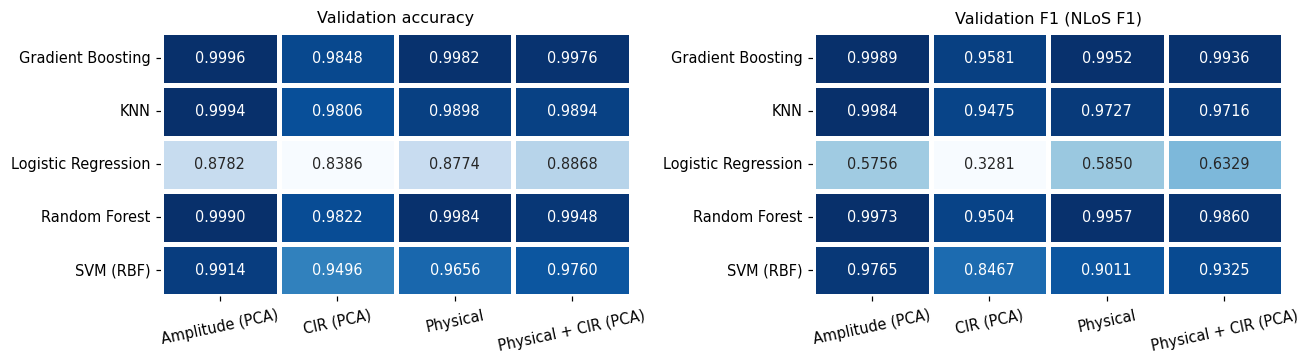

In [16]:
# Figure: ML feature-set comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, metric in zip(axes, ['accuracy', 'F1']):
    sn.heatmap(feature_table.pivot(index='model', columns='feature set', values=metric)[FEATURE_SETS],
               annot=True, fmt='.4f', cmap='Blues', cbar=False, ax=ax, linewidths=2, linecolor='white')
    ax.set(title=f'Validation {metric} (NLoS F1)' if metric == 'F1' else f'Validation {metric}', xlabel='', ylabel='')
    ax.tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

## 4. Configurations of every ML model
Each model is tuned on the input format that suits it: the PCA amplitude features for Logistic Regression, KNN and SVM,
the 46 physical features for the tree ensembles (they are as accurate as PCA features here, 35× smaller and interpretable).
For the PCA grids, PCA is fitted once with 400 components and the first *n* columns give the *n*-component features.

In [17]:
pca400 = PCA(400, random_state=SEED).fit(X_train['Amplitude (PCA)'])
Z_train, Z_valid = pca400.transform(X_train['Amplitude (PCA)']), pca400.transform(X_valid['Amplitude (PCA)'])
print('variance kept by 10 / 50 / 100 / 400 components:',
      [round(pca400.explained_variance_ratio_[:n].sum(), 4) for n in [10, 50, 100, 400]])


def grid_row(model, X_tr, X_te, **config):
    r, _, _ = fit_ml(model, X_tr, y_train, X_te, y_valid)
    return {**config, **{k: r[k] for k in ['accuracy', 'F1', 'AUC', 'train_s', 'infer_ms']}}


def best_row(table):
    """Highest F1, then accuracy, then the fastest training."""
    return table.sort_values(['F1', 'accuracy', 'train_s'], ascending=[False, False, True]).iloc[0]

variance kept by 10 / 50 / 100 / 400 components: [np.float32(0.8987), np.float32(0.9771), np.float32(0.9933), np.float32(0.9993)]


### 4.1 Logistic Regression — number of PCA components × regularization strength `C`
Small `C` = strong L2 regularization. A second variant feeds degree-2 polynomial features of the physical features
(46 → 1127 products) to the same linear classifier, to test whether non-linear inputs help a linear model.

In [18]:
rows = []
for n in [20, 50, 100, 200, 400]:
    for C in [0.01, 0.1, 1, 10, 100]:
        rows.append(grid_row(make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)),
                             Z_train[:, :n], Z_valid[:, :n], input='Amplitude (PCA)', PCA=n, C=C))
for C in [0.01, 0.1, 1, 10]:
    model = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                          LogisticRegression(C=C, max_iter=5000))
    rows.append(grid_row(model, X_train['Physical'], X_valid['Physical'], input='Physical (poly-2)', PCA=0, C=C))
lr_grid = pd.DataFrame(rows)
lr_grid.sort_values('F1', ascending=False).head(8).round(4)

,input,PCA,C,accuracy,F1,AUC,train_s,infer_ms
27,Physical (poly-2),0,1.00,0.9922,0.9791,0.9987,2.7975,0.0319
28,Physical (poly-2),0,10.00,0.9916,0.9775,0.9985,4.1242,0.0335
22,Amplitude (PCA),400,1.00,0.9890,0.9705,0.9988,0.5298,0.0083
23,Amplitude (PCA),400,10.00,0.9886,0.9696,0.9984,0.2878,0.0034
21,Amplitude (PCA),400,0.10,0.9868,0.9643,0.9982,0.4644,0.0090
24,Amplitude (PCA),400,100.00,0.9854,0.9611,0.9979,0.2218,0.0018
26,Physical (poly-2),0,0.10,0.9812,0.9486,0.9967,1.9834,0.0166
20,Amplitude (PCA),400,0.01,0.9758,0.9323,0.9942,0.3556,0.0080


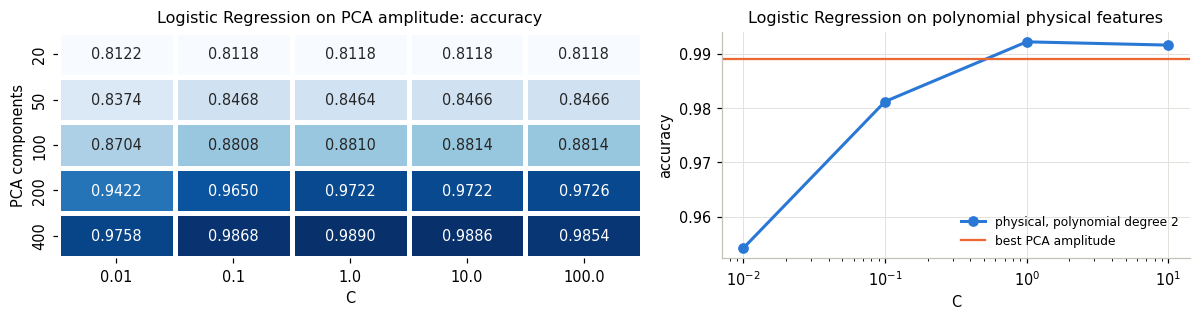

In [19]:
# Figure: Logistic Regression grid
fig, axes = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={'width_ratios': [5, 4]})
sn.heatmap(lr_grid.query("input == 'Amplitude (PCA)'").pivot(index='PCA', columns='C', values='accuracy'),
           annot=True, fmt='.4f', cmap='Blues', cbar=False, ax=axes[0], linewidths=2, linecolor='white')
axes[0].set(title='Logistic Regression on PCA amplitude: accuracy', ylabel='PCA components')
poly = lr_grid.query("input == 'Physical (poly-2)'")
axes[1].plot(poly['C'], poly['accuracy'], marker='o', label='physical, polynomial degree 2')
axes[1].axhline(lr_grid.query("input == 'Amplitude (PCA)'")['accuracy'].max(), color=PALETTE[1], lw=1.5,
                label='best PCA amplitude')
axes[1].set(xscale='log', xlabel='C', ylabel='accuracy', title='Logistic Regression on polynomial physical features')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4.2 KNN — number of neighbours `k` × number of PCA components

In [20]:
rows = []
for n in [10, 20, 50, 100, 200]:
    for k in [1, 3, 5, 9, 15, 31]:
        rows.append(grid_row(KNeighborsClassifier(n_neighbors=k), Z_train[:, :n], Z_valid[:, :n], PCA=n, k=k))
knn_grid = pd.DataFrame(rows)
knn_grid.sort_values('F1', ascending=False).head(6).round(4)

,PCA,k,accuracy,F1,AUC,train_s,infer_ms
24,200,1,1.0000,1.0000,1.0000,0.0165,0.1463
18,100,1,1.0000,1.0000,1.0000,0.0085,0.1267
12,50,1,0.9998,0.9995,0.9995,0.0044,0.1040
25,200,3,0.9996,0.9989,1.0000,0.0148,0.1672
19,100,3,0.9996,0.9989,1.0000,0.0074,0.1252
6,20,1,0.9996,0.9989,0.9989,0.0000,0.1012


### 4.3 SVM (RBF kernel) — penalty `C` × kernel width `gamma` (100 standardized PCA components)

In [21]:
rows = []
for C in [0.1, 1, 10, 100]:
    for gamma in [0.001, 0.01, 0.1]:
        rows.append(grid_row(make_pipeline(StandardScaler(), SVC(C=C, gamma=gamma)), Z_train[:, :100], Z_valid[:, :100],
                             C=C, gamma=gamma))
svm_grid = pd.DataFrame(rows)
svm_grid.sort_values('F1', ascending=False).head(6).round(4)

,C,gamma,accuracy,F1,AUC,train_s,infer_ms
10,100.0,0.010,0.9998,0.9995,1.0000,1.5939,0.0966
11,100.0,0.100,0.9976,0.9935,1.0000,7.6144,0.5863
5,1.0,0.100,0.9976,0.9935,1.0000,6.8786,0.5836
8,10.0,0.100,0.9976,0.9935,1.0000,8.0617,0.5778
7,10.0,0.010,0.9970,0.9919,1.0000,2.3267,0.1518
9,100.0,0.001,0.9934,0.9821,0.9993,5.3527,0.2703


### 4.4 Random Forest — number of trees × maximum depth (physical features)

In [22]:
rows = []
for n_trees in [25, 100, 300]:
    for depth in [4, 8, 16, None]:
        model = RandomForestClassifier(n_estimators=n_trees, max_depth=depth, n_jobs=-1, random_state=SEED)
        rows.append(grid_row(model, X_train['Physical'], X_valid['Physical'], trees=n_trees,
                             max_depth=str(depth)))
rf_grid = pd.DataFrame(rows)
rf_grid.sort_values('F1', ascending=False).head(6).round(4)

,trees,max_depth,accuracy,F1,AUC,train_s,infer_ms
11,300,None,0.9986,0.9962,1.0,4.9086,0.0380
6,100,16,0.9984,0.9957,1.0,1.7051,0.0176
10,300,16,0.9984,0.9957,1.0,4.9169,0.0410
2,25,16,0.9978,0.9941,1.0,0.5901,0.0103
7,100,None,0.9978,0.9941,1.0,1.7237,0.0285
3,25,None,0.9976,0.9936,1.0,0.5199,0.0097


### 4.5 Gradient Boosting — learning rate × leaves per tree (physical features)

In [23]:
rows = []
for lr in [0.03, 0.1, 0.3]:
    for leaves in [7, 15, 31, 63]:
        model = HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, max_iter=300, random_state=SEED)
        rows.append(grid_row(model, X_train['Physical'], X_valid['Physical'], learning_rate=lr, leaves=leaves))
gb_grid = pd.DataFrame(rows)
gb_grid.sort_values('F1', ascending=False).head(6).round(4)

,learning_rate,leaves,accuracy,F1,AUC,train_s,infer_ms
10,0.3,31,0.9992,0.9979,0.9998,1.4485,0.0062
6,0.1,31,0.9992,0.9979,1.0000,4.1666,0.0193
9,0.3,15,0.9990,0.9973,1.0000,1.7815,0.0082
5,0.1,15,0.9990,0.9973,0.9998,3.0588,0.0222
11,0.3,63,0.9990,0.9973,1.0000,2.2157,0.0033
8,0.3,7,0.9988,0.9968,0.9999,1.5410,0.0139


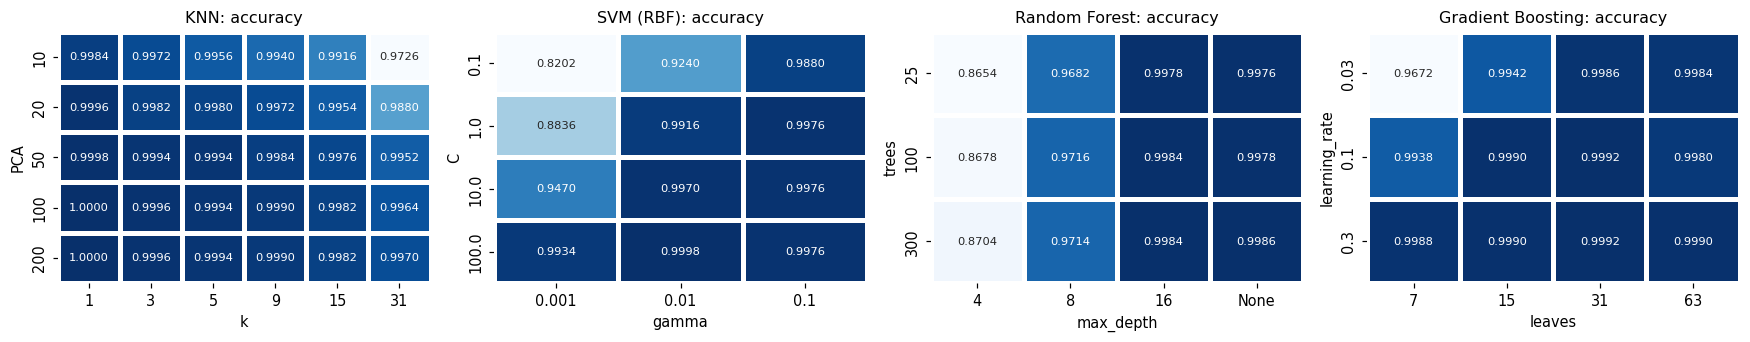

In [24]:
# Figure: KNN, SVM, Random Forest and Gradient Boosting grids
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (table, title) in zip(axes, [
        (knn_grid.pivot(index='PCA', columns='k', values='accuracy'), 'KNN: accuracy'),
        (svm_grid.pivot(index='C', columns='gamma', values='accuracy'), 'SVM (RBF): accuracy'),
        (rf_grid.pivot(index='trees', columns='max_depth', values='accuracy')[['4', '8', '16', 'None']], 'Random Forest: accuracy'),
        (gb_grid.pivot(index='learning_rate', columns='leaves', values='accuracy'), 'Gradient Boosting: accuracy')]):
    sn.heatmap(table, annot=True, fmt='.4f', cmap='Blues',
               cbar=False, ax=ax, linewidths=2, linecolor='white', annot_kws={'fontsize': 7.5})
    ax.set(title=title)
plt.tight_layout()
plt.show()

### 4.6 Final ML models
The best configuration of every model is rebuilt as one complete pipeline (raw input → PCA / scaling → model) and
trained again, so that the reported training time, inference time and size include the pre-processing step.

In [25]:
best = {'Logistic Regression': best_row(lr_grid), 'KNN': best_row(knn_grid), 'SVM (RBF)': best_row(svm_grid),
        'Random Forest': best_row(rf_grid), 'Gradient Boosting': best_row(gb_grid)}
for name, row in best.items():
    print(f'{name:20s}', {k: v for k, v in row.items() if k not in ['accuracy', 'F1', 'AUC', 'train_s', 'infer_ms']})

b = best['Logistic Regression']
if b['input'] == 'Physical (poly-2)':
    lr_final = ('Physical', make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                                          LogisticRegression(C=b['C'], max_iter=5000)))
else:
    lr_final = ('Amplitude (PCA)', ml_pipeline('Amplitude (PCA)', LogisticRegression(C=b['C'], max_iter=3000), int(b['PCA'])))
b_rf, b_gb = best['Random Forest'], best['Gradient Boosting']
final_ml = {
    'Logistic Regression': lr_final,
    'SVM (RBF)': ('Amplitude (PCA)', ml_pipeline('Amplitude (PCA)', SVC(C=best['SVM (RBF)']['C'], gamma=best['SVM (RBF)']['gamma']))),
    'KNN': ('Amplitude (PCA)', ml_pipeline('Amplitude (PCA)', KNeighborsClassifier(int(best['KNN']['k'])),
                                           int(best['KNN']['PCA']), scale=False)),
    'Random Forest': ('Physical', ml_pipeline('Physical', RandomForestClassifier(
        n_estimators=int(b_rf['trees']), max_depth=None if b_rf['max_depth'] == 'None' else int(b_rf['max_depth']),
        n_jobs=-1, random_state=SEED))),
    'Gradient Boosting': ('Physical', ml_pipeline('Physical', HistGradientBoostingClassifier(
        learning_rate=b_gb['learning_rate'], max_leaf_nodes=int(b_gb['leaves']), max_iter=300, random_state=SEED)))}

Logistic Regression  {'input': 'Physical (poly-2)', 'PCA': np.int64(0), 'C': np.float64(1.0)}
KNN                  {'PCA': 100.0, 'k': 1.0}
SVM (RBF)            {'C': 100.0, 'gamma': 0.01}
Random Forest        {'trees': np.int64(300), 'max_depth': 'None'}
Gradient Boosting    {'learning_rate': 0.3, 'leaves': 31.0}


Efficiency: besides the batch inference time on the 5000 validation samples, the **latency for one sample** is
measured (median of 100 calls, one CPU thread for PyTorch), which is what matters for a vehicle that is positioned
one CSI report at a time.

In [26]:
def cpu_latency_ms(fn, runs=100):
    threads = torch.get_num_threads()
    torch.set_num_threads(1)
    for _ in range(10):
        fn()
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    torch.set_num_threads(threads)
    return 1000 * float(np.median(times))


def ml_latency(model, X):
    est = model[-1]
    n_jobs = getattr(est, 'n_jobs', None)
    if hasattr(est, 'n_jobs'):
        est.n_jobs = 1                    # no thread pool for a single sample
    latency = cpu_latency_ms(lambda: model.predict(X[:1]))
    if hasattr(est, 'n_jobs'):
        est.n_jobs = n_jobs
    return latency


ml_rows, ml_pred, ml_score = [], {}, {}
for name, (fs, model) in final_ml.items():
    r, ml_pred[name], ml_score[name] = fit_ml(model, X_train[fs], y_train, X_valid[fs], y_valid)
    ml_rows.append({'model': name, 'type': 'ML', 'input': fs, **r, 'params': np.nan,
                    'cpu_latency_ms': ml_latency(model, X_valid[fs])})
ml_table = pd.DataFrame(ml_rows).set_index('model')
ml_table.round(4)

,type,input,accuracy,precision,recall,F1,AUC,train_s,infer_ms,size_MB,params,cpu_latency_ms
model,,,,,,,,,,,,
Logistic Regression,ML,Physical,0.9922,0.9817,0.9765,0.9791,0.9987,3.9756,0.0263,0.0387,NaN,0.5084
SVM (RBF),ML,Amplitude (PCA),0.9998,1.0000,0.9989,0.9995,1.0000,2.6224,0.0776,1.0957,NaN,0.3494
KNN,ML,Amplitude (PCA),1.0000,1.0000,1.0000,1.0000,1.0000,1.3918,0.0382,6.7819,NaN,1.7482
Random Forest,ML,Physical,0.9986,1.0000,0.9925,0.9962,1.0000,1.9363,0.0204,14.0342,NaN,6.1562
Gradient Boosting,ML,Physical,0.9992,1.0000,0.9957,0.9979,0.9998,0.5664,0.0026,0.3365,NaN,1.7551


In [27]:
best_ml = ml_table.sort_values(['F1', 'accuracy', 'cpu_latency_ms'], ascending=[False, False, True]).index[0]
print('best ML model:', best_ml)
print(classification_report(y_valid, ml_pred[best_ml], target_names=CLASSES, digits=4))

best ML model: KNN
              precision    recall  f1-score   support

         LoS     1.0000    1.0000    1.0000      4064
        NLoS     1.0000    1.0000    1.0000       936

    accuracy                         1.0000      5000
   macro avg     1.0000    1.0000    1.0000      5000
weighted avg     1.0000    1.0000    1.0000      5000



**Which physical features matter?** Impurity-based importance of the final Random Forest (top 15).

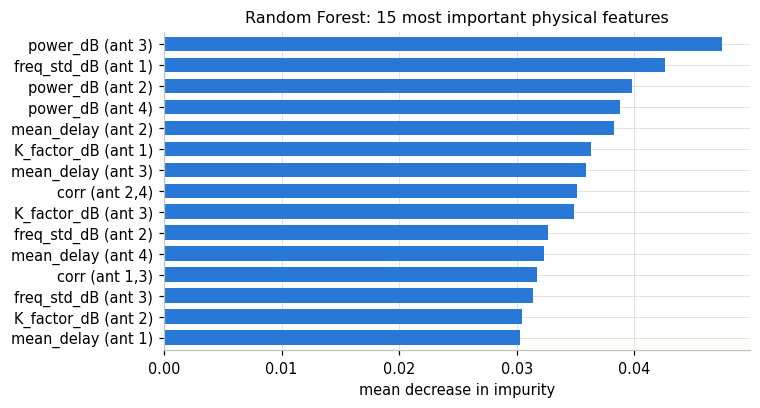

importance summed over the antennas:
corr              0.173
power_dB          0.153
mean_delay        0.137
freq_std_dB       0.127
K_factor_dB       0.122
peak_tap          0.075
kurtosis          0.062
first_path_tap    0.060
rms_delay         0.057
peak_ratio_dB     0.029
first_path_dB     0.007


In [28]:
# Figure: Random Forest feature importance
rf = final_ml['Random Forest'][1][-1]
importance = pd.Series(rf.feature_importances_, index=PHYS_NAMES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.8))
importance.head(15)[::-1].plot.barh(ax=ax, color=PALETTE[0], width=0.7)
ax.set(xlabel='mean decrease in impurity', title='Random Forest: 15 most important physical features')
plt.tight_layout()
plt.show()
per_feature = pd.Series({f: importance[[n for n in PHYS_NAMES if n.startswith(f)]].sum() for f in PER_ANTENNA + ['corr']})
print('importance summed over the antennas:')
print(per_feature.sort_values(ascending=False).round(3).to_string())

# Part B — Artificial neural networks
## 5. ANN design
**Inputs.** The networks learn their own features from the normalized amplitude image (4 × 408, the 4 antennas
are the 4 input channels of the 1-D convolutions), from the CIR (4 × 128) or from both (fusion network).

| Network | Structure |
|---|---|
| MLP | flatten (1632) → 512 → 256 → output; dropout 0.2 |
| CNN-1D | 3 × [Conv1d (k = 7, 5, 3) → BatchNorm → activation → pooling], 32/64/128 channels → FC 128 → output |
| CNN-2D | the CSI as a 1-channel image; kernels (3×7), (3×5) and (4×3) — the last one mixes all 4 antennas |
| ResNet-1D | stem conv + 4 residual blocks (two 3-tap convolutions + skip connection), global average pooling |
| CNN-BiGRU | 2 conv blocks shorten the sequence to 102 steps, a bidirectional GRU (64 units) reads it along frequency |
| Transformer | patches of 8 subcarriers × 4 antennas → 51 tokens of size 64, 2 self-attention layers (4 heads) |
| CIR-CNN | the CNN-1D applied to the CIR |
| Fusion CNN | one convolution branch for |H| and one for the CIR; their features are concatenated before the FC head |

**Activation functions.** ReLU in the hidden layers (LeakyReLU, ELU, GELU, Tanh and Sigmoid are compared in 6.2).

**Output.** 2 neurons (logits of LoS / NLoS) followed by **softmax**; the loss is the cross-entropy and the
predicted class is the arg-max. A single sigmoid neuron with binary cross-entropy and a class-weighted
cross-entropy (NLoS is only 18 % of the data) are compared in 6.2.

**Training.** Adam, learning rate 1e-3 with cosine decay over `MAX_EPOCHS` epochs, batch size 64, mini-batches drawn
from tensors that stay on the GPU. **Early stopping** monitors the validation cross-entropy after every epoch, stops
after `PATIENCE` epochs without improvement and restores the best checkpoint.

In [29]:
def conv_block(c_in, c_out, k, act, pool):
    return [nn.Conv1d(c_in, c_out, k, padding=k // 2), nn.BatchNorm1d(c_out), act(), pool]


def make_mlp(n_out, n_in=4 * 408, act=nn.ReLU, hidden=(512, 256), dropout=0.2):
    layers, prev = [nn.Flatten()], n_in
    for h in hidden:
        layers += [nn.Linear(prev, h), act(), nn.Dropout(dropout)]
        prev = h
    return nn.Sequential(*layers, nn.Linear(prev, n_out))


def make_cnn1d(n_out, c_in=4, act=nn.ReLU, channels=(32, 64, 128), dropout=0.2):
    c1, c2, c3 = channels
    return nn.Sequential(*conv_block(c_in, c1, 7, act, nn.MaxPool1d(2)),
                         *conv_block(c1, c2, 5, act, nn.MaxPool1d(2)),
                         *conv_block(c2, c3, 3, act, nn.AdaptiveAvgPool1d(8)),
                         nn.Flatten(), nn.Linear(c3 * 8, 128), act(), nn.Dropout(dropout), nn.Linear(128, n_out))


class CNN2D(nn.Module):
    def __init__(self, n_out, act=nn.ReLU):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, (3, 7), padding=(1, 3)), nn.BatchNorm2d(16), act(), nn.MaxPool2d((1, 2)),
            nn.Conv2d(16, 32, (3, 5), padding=(1, 2)), nn.BatchNorm2d(32), act(), nn.MaxPool2d((1, 2)),
            nn.Conv2d(32, 64, (4, 3), padding=(0, 1)), nn.BatchNorm2d(64), act(), nn.AdaptiveAvgPool2d((1, 8)),
            nn.Flatten(), nn.Linear(64 * 8, 128), act(), nn.Dropout(0.2), nn.Linear(128, n_out))

    def forward(self, x):
        return self.net(x.unsqueeze(1))


class ResBlock1D(nn.Module):
    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.conv1, self.bn1 = nn.Conv1d(c_in, c_out, 3, stride, 1, bias=False), nn.BatchNorm1d(c_out)
        self.conv2, self.bn2 = nn.Conv1d(c_out, c_out, 3, 1, 1, bias=False), nn.BatchNorm1d(c_out)
        self.skip = (nn.Identity() if c_in == c_out and stride == 1 else
                     nn.Sequential(nn.Conv1d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm1d(c_out)))

    def forward(self, x):
        return F.relu(self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x))))) + self.skip(x))


class ResNet1D(nn.Module):
    def __init__(self, n_out, c_in=4):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(c_in, 32, 7, 2, 3, bias=False), nn.BatchNorm1d(32), nn.ReLU(),
                                 ResBlock1D(32, 32, 1), ResBlock1D(32, 64, 2), ResBlock1D(64, 128, 2),
                                 ResBlock1D(128, 128, 2), nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(128, n_out))

    def forward(self, x):
        return self.net(x)


class CNNBiGRU(nn.Module):
    def __init__(self, n_out, c_in=4, hidden=64):
        super().__init__()
        self.conv = nn.Sequential(*conv_block(c_in, 32, 7, nn.ReLU, nn.MaxPool1d(2)),
                                  *conv_block(32, 64, 5, nn.ReLU, nn.MaxPool1d(2)))
        self.gru = nn.GRU(64, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Linear(2 * hidden, n_out)

    def forward(self, x):
        out, _ = self.gru(self.conv(x).transpose(1, 2))
        return self.head(out.mean(1))


class TransformerNet(nn.Module):
    def __init__(self, n_out, c_in=4, length=408, patch=8, d_model=64):
        super().__init__()
        self.embed = nn.Conv1d(c_in, d_model, patch, stride=patch)
        self.pos = nn.Parameter(torch.zeros(1, length // patch, d_model))
        layer = nn.TransformerEncoderLayer(d_model, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)
        self.head = nn.Linear(d_model, n_out)

    def forward(self, x):
        return self.head(self.encoder(self.embed(x).transpose(1, 2) + self.pos).mean(1))


class FusionCNN(nn.Module):
    def __init__(self, n_out):
        super().__init__()
        self.amp = nn.Sequential(*conv_block(4, 32, 7, nn.ReLU, nn.MaxPool1d(2)), *conv_block(32, 64, 5, nn.ReLU, nn.MaxPool1d(2)),
                                 *conv_block(64, 64, 3, nn.ReLU, nn.AdaptiveAvgPool1d(8)), nn.Flatten())
        self.cir = nn.Sequential(*conv_block(4, 32, 5, nn.ReLU, nn.MaxPool1d(2)),
                                 *conv_block(32, 64, 3, nn.ReLU, nn.AdaptiveAvgPool1d(8)), nn.Flatten())
        self.head = nn.Sequential(nn.Linear(2 * 64 * 8, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, n_out))

    def forward(self, amp, cir):
        return self.head(torch.cat([self.amp(amp), self.cir(cir)], dim=1))


ARCHS = {'MLP': (('amp',), lambda n_out: make_mlp(n_out)),
         'CNN-1D': (('amp',), lambda n_out: make_cnn1d(n_out)),
         'CNN-2D': (('amp',), lambda n_out: CNN2D(n_out)),
         'ResNet-1D': (('amp',), lambda n_out: ResNet1D(n_out)),
         'CNN-BiGRU': (('amp',), lambda n_out: CNNBiGRU(n_out)),
         'Transformer': (('amp',), lambda n_out: TransformerNet(n_out)),
         'CIR-CNN': (('cir',), lambda n_out: make_cnn1d(n_out)),
         'Fusion CNN': (('amp', 'cir'), lambda n_out: FusionCNN(n_out))}

### Training and evaluation functions

In [30]:
def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()


def make_optimizer(name, params, lr):
    if name == 'Adam':
        return torch.optim.Adam(params, lr=lr)
    if name == 'AdamW':
        return torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)
    if name == 'SGD':
        return torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True)
    return torch.optim.RMSprop(params, lr=lr)


@torch.no_grad()
def net_output(model, inputs, batch_size=1000):
    model.eval()
    return torch.cat([model(*(x[i:i + batch_size] for x in inputs)) for i in range(0, len(inputs[0]), batch_size)])


def nlos_prob(model, inputs, head='softmax'):
    out = net_output(model, inputs)
    prob = out.softmax(1)[:, 1] if head == 'softmax' else torch.sigmoid(out[:, 0])
    return prob.cpu().numpy()


def train_net(model, inputs, y, val_inputs, y_val, max_epochs=MAX_EPOCHS, patience=PATIENCE, lr=1e-3, batch_size=64,
              optimizer='Adam', head='softmax', class_weight=None, transform=None, verbose=False):
    """Mini-batch training with cosine learning-rate decay over `max_epochs` and early stopping on the validation
    cross-entropy: training stops after `patience` epochs without improvement and the best checkpoint is restored.
    Returns the history per epoch (history.attrs['best_epoch']) and the training time (s).
    `transform` maps a raw training batch to the network input (used for data augmentation)."""
    model.to(device)
    opt = make_optimizer(optimizer, model.parameters(), lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    if head == 'softmax':
        loss_fn, target = nn.CrossEntropyLoss(weight=class_weight), torch.as_tensor(y, device=device).long()
    else:
        loss_fn, target = nn.BCEWithLogitsLoss(), torch.as_tensor(y, device=device).float()
    history, train_time = [], 0.0
    best_loss, best_epoch, best_state = np.inf, 0, None
    for epoch in range(max_epochs):
        model.train()
        sync()
        start = time.time()
        perm = torch.randperm(len(target), device=device)
        total = torch.zeros((), device=device)
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2:
                continue
            xb = tuple(x[idx] for x in inputs)
            if transform is not None:
                xb = transform(*xb)
            out = model(*xb)
            loss = loss_fn(out if head == 'softmax' else out[:, 0], target[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.detach() * len(idx)
        scheduler.step()
        sync()
        train_time += time.time() - start
        prob = nlos_prob(model, val_inputs, head)
        history.append({'epoch': epoch + 1, 'train_loss': total.item() / len(perm),
                        'val_loss': log_loss(y_val, np.clip(prob, 1e-7, 1 - 1e-7), labels=[0, 1]),
                        'val_acc': accuracy_score(y_val, (prob > 0.5).astype(int))})
        if verbose:
            print('  epoch %2d | train loss %.4f | val loss %.4f | val acc %.4f' % tuple(history[-1].values()))
        if history[-1]['val_loss'] < best_loss:
            best_loss, best_epoch = history[-1]['val_loss'], epoch + 1
            best_state = copy.deepcopy(model.state_dict())
        elif epoch + 1 - best_epoch >= patience:
            break
    model.load_state_dict(best_state)                 # best validation checkpoint
    history = pd.DataFrame(history)
    history.attrs['best_epoch'] = best_epoch
    if verbose:
        print(f'  early stopping after {len(history)} epochs, best checkpoint: epoch {best_epoch}')
    return history, train_time


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / 1e6


def batch_infer_ms(model, inputs, repeats=3):
    net_output(model, inputs)
    best_time = np.inf
    for _ in range(repeats):
        sync()
        start = time.time()
        net_output(model, inputs)
        sync()
        best_time = min(best_time, time.time() - start)
    return 1000 * best_time / len(inputs[0])


def ann_latency(model, inputs):
    cpu_model = copy.deepcopy(model).cpu().eval()
    x1 = tuple(x[:1].cpu() for x in inputs)
    with torch.no_grad():
        return cpu_latency_ms(lambda: cpu_model(*x1))

## 6. Results of the ANN methods
### 6.1 Architecture comparison
Every network is trained with the same recipe (Section 5), at most `MAX_EPOCHS` epochs with early stopping. The log of
the 1-D CNN is printed as an example of a run.

In [31]:
ann_models, ann_hist, ann_prob, ann_rows = {}, {}, {}, []
for name, (keys, build) in ARCHS.items():
    set_seed()
    model = build(2)
    tr, va = tuple(train_gpu[k] for k in keys), tuple(valid_gpu[k] for k in keys)
    if name == 'CNN-1D':
        print('training log of CNN-1D:')
    hist, train_s = train_net(model, tr, y_train, va, y_valid, verbose=(name == 'CNN-1D'))
    prob = nlos_prob(model, va)
    ann_models[name], ann_hist[name], ann_prob[name] = model, hist, prob
    ann_rows.append({'model': name, 'type': 'ANN', 'input': ' + '.join(keys), **cls_metrics(y_valid, (prob > 0.5).astype(int), prob),
                     'train_s': train_s, 'infer_ms': batch_infer_ms(model, va), 'size_MB': size_mb(model),
                     'params': count_params(model), 'cpu_latency_ms': ann_latency(model, va),
                     'val_loss': hist['val_loss'].min(), 'best_epoch': hist.attrs['best_epoch'], 'epochs_run': len(hist)})
    print(f'{name:12s} accuracy {ann_rows[-1]["accuracy"]:.4f} | F1 {ann_rows[-1]["F1"]:.4f} | '
          f'{ann_rows[-1]["params"]:9,d} parameters | best epoch {hist.attrs["best_epoch"]:2d} of {len(hist):2d} | '
          f'training {train_s:5.1f} s')
ann_table = pd.DataFrame(ann_rows).set_index('model')
ann_table.round(4)

MLP          accuracy 0.9998 | F1 0.9995 |   967,938 parameters | best epoch 23 of 25 | training  32.6 s
training log of CNN-1D:


  epoch  1 | train loss 0.3012 | val loss 0.5321 | val acc 0.6966


  epoch  2 | train loss 0.1462 | val loss 0.5774 | val acc 0.7440


  epoch  3 | train loss 0.0693 | val loss 0.0351 | val acc 0.9878


  epoch  4 | train loss 0.0357 | val loss 0.0295 | val acc 0.9910


...

CNN-BiGRU    accuracy 1.0000 | F1 1.0000 |    61,602 parameters | best epoch 20 of 25 | training  42.1 s


Transformer  accuracy 0.9998 | F1 0.9995 |    72,450 parameters | best epoch 15 of 20 | training  66.5 s


CIR-CNN      accuracy 0.9980 | F1 0.9947 |   167,842 parameters | best epoch 11 of 16 | training  27.0 s


Fusion CNN   accuracy 1.0000 | F1 1.0000 |   162,434 parameters | best epoch 25 of 25 | training  58.0 s


,type,input,accuracy,precision,recall,F1,AUC,train_s,infer_ms,size_MB,params,cpu_latency_ms,val_loss,best_epoch,epochs_run
model,,,,,,,,,,,,,,,
MLP,ANN,amp,0.9998,1.0000,0.9989,0.9995,1.0000,32.6246,0.0006,3.8746,967938,0.3125,0.0026,23,25
CNN-1D,ANN,amp,1.0000,1.0000,1.0000,1.0000,1.0000,59.0470,0.0078,0.6810,167842,1.2437,0.0001,25,25
CNN-2D,ANN,amp,1.0000,1.0000,1.0000,1.0000,1.0000,55.4111,0.0127,0.4044,98850,2.4601,0.0000,24,25
ResNet-1D,ANN,amp,1.0000,1.0000,1.0000,1.0000,1.0000,85.5492,0.0081,0.9382,226498,1.3186,0.0001,25,25
CNN-BiGRU,ANN,amp,1.0000,1.0000,1.0000,1.0000,1.0000,42.0722,0.0087,0.2535,61602,7.2106,0.0002,20,25
Transformer,ANN,amp,0.9998,0.9989,1.0000,0.9995,1.0000,66.4673,0.0056,0.3001,72450,1.0340,0.0013,15,20
CIR-CNN,ANN,cir,0.9980,0.9947,0.9947,0.9947,0.9999,27.0335,0.0012,0.6810,167842,0.6640,0.0069,11,16
Fusion CNN,ANN,amp + cir,1.0000,1.0000,1.0000,1.0000,1.0000,57.9725,0.0062,0.6644,162434,1.7001,0.0001,25,25


The best validation checkpoint (highest NLoS F1, then lowest validation cross-entropy) is saved with everything needed
to reuse it: architecture, input, scaling statistics of the training set and the best epoch.

In [32]:
ckpt_name = ann_table.sort_values(['F1', 'accuracy', 'val_loss'], ascending=[False, False, True]).index[0]
torch.save({'architecture': ckpt_name, 'inputs': ARCHS[ckpt_name][0], 'state_dict': ann_models[ckpt_name].state_dict(),
            'best_epoch': int(ann_table.loc[ckpt_name, 'best_epoch']), 'scaling': vars(norm), 'pool': POOL,
            'n_taps': N_TAPS, 'classes': CLASSES}, 'LoS_best_model.pt')
print(f'saved LoS_best_model.pt: {ckpt_name}, best epoch {int(ann_table.loc[ckpt_name, "best_epoch"])}, '
      f'validation cross-entropy {ann_table.loc[ckpt_name, "val_loss"]:.5f}')

saved LoS_best_model.pt: CNN-2D, best epoch 24, validation cross-entropy 0.00002


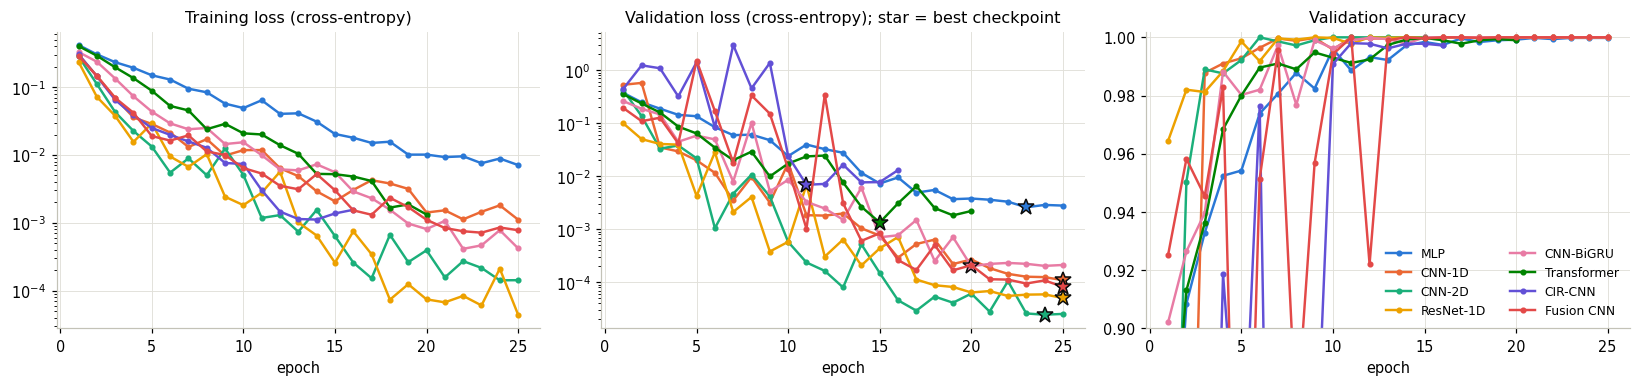

In [33]:
# Figure: ANN training curves
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for i, (name, hist) in enumerate(ann_hist.items()):
    for ax, col in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
        ax.plot(hist['epoch'], hist[col], marker='o', ms=3, lw=1.6, color=PALETTE[i], label=name)
    b = hist.attrs['best_epoch']
    axes[1].plot(b, hist.loc[b - 1, 'val_loss'], marker='*', ms=11, color=PALETTE[i], markeredgecolor='#0b0b0b')
axes[0].set(title='Training loss (cross-entropy)', xlabel='epoch', yscale='log')
axes[1].set(title='Validation loss (cross-entropy); star = best checkpoint', xlabel='epoch', yscale='log')
axes[2].set(title='Validation accuracy', xlabel='epoch', ylim=(0.9, 1.002))
axes[2].legend(fontsize=8, loc='lower right', ncol=2)
plt.tight_layout()
plt.show()

### 6.2 Configuration study (CNN-1D)
One design choice is changed at a time; everything else is the baseline of Section 5 (ReLU, 2 softmax outputs,
Adam, lr 1e-3, batch 64, linear min-max input). Because the accuracy on known positions is close to 100 % for most
settings, the validation **cross-entropy** and the number of epochs needed to reach 99 % accuracy are reported too —
they show differences in confidence and convergence speed that accuracy hides.

In [34]:
CLASS_WEIGHT = torch.tensor(len(y_train) / (2 * np.bincount(y_train)), dtype=torch.float32, device=device)


def run_config(study, setting, act=nn.ReLU, head='softmax', class_weight=None, optimizer='Adam', lr=1e-3,
               batch_size=64, input_key='amp'):
    set_seed()
    model = make_cnn1d(2 if head == 'softmax' else 1, act=act)
    hist, train_s = train_net(model, (train_gpu[input_key],), y_train, (valid_gpu[input_key],), y_valid, lr=lr,
                              batch_size=batch_size, optimizer=optimizer, head=head, class_weight=class_weight)
    prob = nlos_prob(model, (valid_gpu[input_key],), head)
    reached = hist.loc[hist['val_acc'] >= 0.99, 'epoch']
    return {'study': study, 'setting': setting, **cls_metrics(y_valid, (prob > 0.5).astype(int), prob),
            'val_loss': hist['val_loss'].min(), 'epochs_to_99%': reached.iloc[0] if len(reached) else np.nan,
            'best_epoch': hist.attrs['best_epoch'], 'train_s': train_s}


STUDIES = {'Hidden activation': ('ReLU', [('LeakyReLU', dict(act=nn.LeakyReLU)), ('ELU', dict(act=nn.ELU)),
                                          ('GELU', dict(act=nn.GELU)), ('Tanh', dict(act=nn.Tanh)),
                                          ('Sigmoid', dict(act=nn.Sigmoid))]),
           'Output layer / loss': ('2 softmax + CE', [('1 sigmoid + BCE', dict(head='sigmoid')),
                                                      ('2 softmax + weighted CE', dict(class_weight=CLASS_WEIGHT))]),
           'Optimizer': ('Adam', [('AdamW (wd 0.01)', dict(optimizer='AdamW')),
                                  ('SGD momentum (lr 0.01)', dict(optimizer='SGD', lr=1e-2)),
                                  ('RMSprop', dict(optimizer='RMSprop'))]),
           'Learning rate': ('1e-3', [('1e-2', dict(lr=1e-2)), ('1e-4', dict(lr=1e-4))]),
           'Batch size': ('64', [('32', dict(batch_size=32)), ('256', dict(batch_size=256))]),
           'Input normalization': ('linear min-max', [('dB min-max', dict(input_key='amp_db')),
                                                      ('per-sample max', dict(input_key='amp_sample'))])}
baseline = run_config('baseline', 'baseline')
rows = []
for study, (base_label, variants) in STUDIES.items():
    rows.append({**baseline, 'study': study, 'setting': base_label + ' (baseline)'})
    for setting, kwargs in variants:
        rows.append(run_config(study, setting, **kwargs))
config_table = pd.DataFrame(rows)
config_table.round(4)

,study,setting,accuracy,precision,recall,F1,AUC,val_loss,epochs_to_99%,best_epoch,train_s
0,Hidden activation,ReLU (baseline),1.0000,1.0000,1.0000,1.0000,1.0000,0.0001,4.0,25,43.2520
1,Hidden activation,LeakyReLU,1.0000,1.0000,1.0000,1.0000,1.0000,0.0001,4.0,25,40.6504
2,Hidden activation,ELU,1.0000,1.0000,1.0000,1.0000,1.0000,0.0002,5.0,25,39.8897
3,Hidden activation,GELU,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,3.0,16,34.2926
4,Hidden activation,Tanh,1.0000,1.0000,1.0000,1.0000,1.0000,0.0001,5.0,25,32.9090
5,Hidden activation,Sigmoid,0.9810,0.9884,0.9092,0.9471,0.9967,0.0629,NaN,25,50.0922
6,Output layer / loss,2 softmax + CE (baseline),1.0000,1.0000,1.0000,1.0000,1.0000,0.0001,4.0,25,43.2520
7,Output layer / loss,1 sigmoid + BCE,1.0000,1.0000,1.0000,1.0000,1.0000,0.0199,4.0,25,56.8003
8,Output layer / loss,2 softmax + weighted CE,1.0000,1.0000,1.0000,1.0000,1.0000,0.0001,3.0,23,36.6592
9,Optimizer,Adam (baseline),1.0000,1.0000,1.0000,1.0000,1.0000,0.0001,4.0,25,43.2520


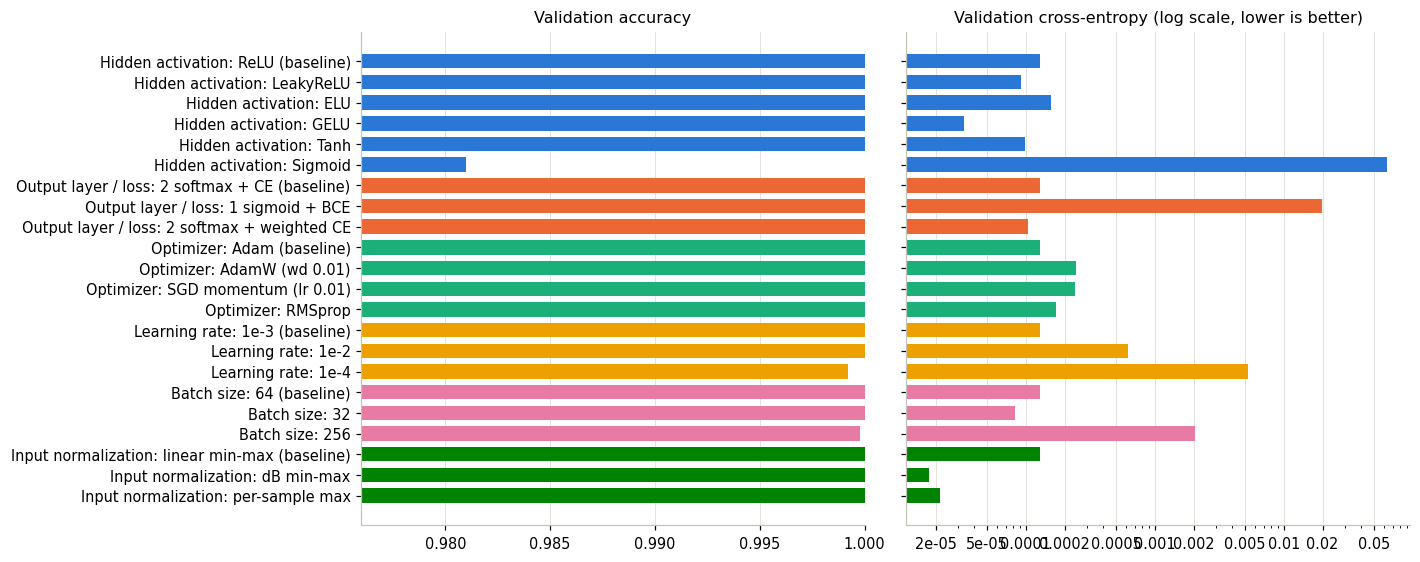

In [35]:
# Figure: configuration study
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
labels = config_table['study'] + ': ' + config_table['setting']
colors = [PALETTE[list(STUDIES).index(s)] for s in config_table['study']]
ypos = np.arange(len(config_table))[::-1]
axes[0].barh(ypos, config_table['accuracy'], color=colors, height=0.7)
axes[0].set(xlim=(max(0.5, config_table['accuracy'].min() - 0.005), 1.0), title='Validation accuracy',
            yticks=ypos, yticklabels=labels)
axes[1].barh(ypos, config_table['val_loss'], color=colors, height=0.7)
log_axis(axes[1])
axes[1].set(title='Validation cross-entropy (log scale, lower is better)')
for ax in axes:
    ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

# Part C — Comparative study of ML and ANN
## 7.1 Accuracy and efficiency of all final models
- **train_s**: wall-clock training time (ML on the CPU including PCA, ANN on the GPU);
- **infer_ms**: prediction time per sample for the 5000 validation samples (batch);
- **cpu_latency_ms**: time to classify one CSI report on the CPU (single sample);
- **size_MB**: storage of the model (pickled scikit-learn pipeline / PyTorch `state_dict` in float32).

In [36]:
summary = pd.concat([ml_table, ann_table])[['type', 'input', 'accuracy', 'precision', 'recall', 'F1', 'AUC', 'train_s',
                                            'infer_ms', 'cpu_latency_ms', 'size_MB', 'params', 'best_epoch']]
summary['params'] = summary['params'].astype('Int64')
summary['best_epoch'] = summary['best_epoch'].astype('Int64')          # ML models have no trainable-weight count
best_ann = ann_table.sort_values(['F1', 'accuracy', 'cpu_latency_ms'], ascending=[False, False, True]).index[0]
print('best ML :', best_ml, '| best ANN:', best_ann)
summary.round(4)

best ML : KNN | best ANN: CNN-1D


,type,input,accuracy,precision,recall,F1,AUC,train_s,infer_ms,cpu_latency_ms,size_MB,params,best_epoch
model,,,,,,,,,,,,,
Logistic Regression,ML,Physical,0.9922,0.9817,0.9765,0.9791,0.9987,3.9756,0.0263,0.5084,0.0387,<NA>,<NA>
SVM (RBF),ML,Amplitude (PCA),0.9998,1.0000,0.9989,0.9995,1.0000,2.6224,0.0776,0.3494,1.0957,<NA>,<NA>
KNN,ML,Amplitude (PCA),1.0000,1.0000,1.0000,1.0000,1.0000,1.3918,0.0382,1.7482,6.7819,<NA>,<NA>
Random Forest,ML,Physical,0.9986,1.0000,0.9925,0.9962,1.0000,1.9363,0.0204,6.1562,14.0342,<NA>,<NA>
Gradient Boosting,ML,Physical,0.9992,1.0000,0.9957,0.9979,0.9998,0.5664,0.0026,1.7551,0.3365,<NA>,<NA>
MLP,ANN,amp,0.9998,1.0000,0.9989,0.9995,1.0000,32.6246,0.0006,0.3125,3.8746,967938,23
CNN-1D,ANN,amp,1.0000,1.0000,1.0000,1.0000,1.0000,59.0470,0.0078,1.2437,0.6810,167842,25
CNN-2D,ANN,amp,1.0000,1.0000,1.0000,1.0000,1.0000,55.4111,0.0127,2.4601,0.4044,98850,24
ResNet-1D,ANN,amp,1.0000,1.0000,1.0000,1.0000,1.0000,85.5492,0.0081,1.3186,0.9382,226498,25


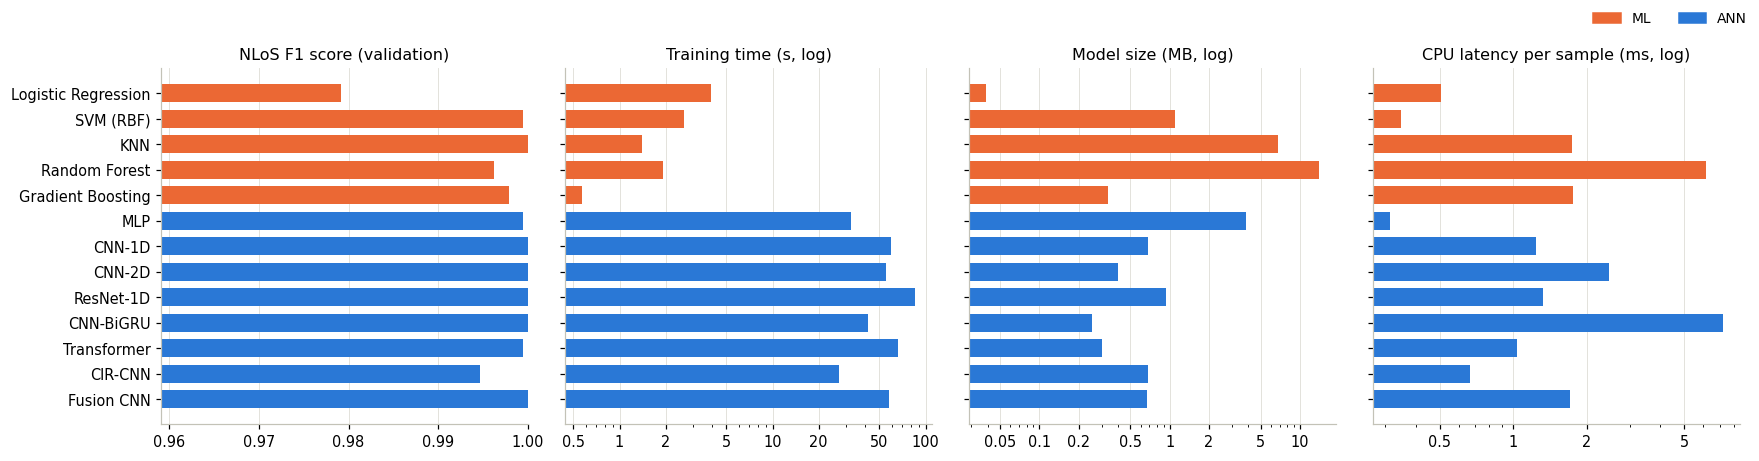

In [37]:
# Figure: comparison of all final models
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
order = summary.index[::-1]
bar_colors = [COLORS[t] for t in summary.loc[order, 'type']]
for ax, (col, title, log) in zip(axes, [('F1', 'NLoS F1 score (validation)', False),
                                        ('train_s', 'Training time (s, log)', True),
                                        ('size_MB', 'Model size (MB, log)', True),
                                        ('cpu_latency_ms', 'CPU latency per sample (ms, log)', True)]):
    ax.barh(range(len(order)), summary.loc[order, col], color=bar_colors, height=0.7)
    ax.set(title=title, yticks=range(len(order)), yticklabels=order)
    ax.grid(axis='y', visible=False)
    if log:
        log_axis(ax)
    else:
        ax.set_xlim(max(0.5, summary[col].min() - 0.02), 1.0)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[t]) for t in ['ML', 'ANN']], labels=['ML', 'ANN'],
           loc='upper right', ncol=2, fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 7.2 Confusion matrices and where the errors are

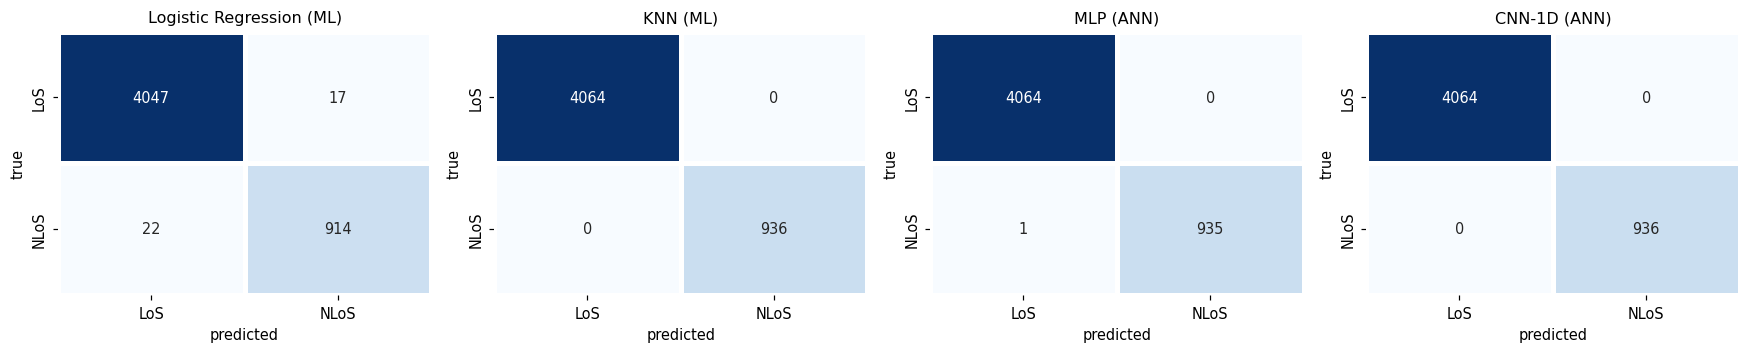

In [38]:
# Figure: confusion matrices
shown = {'Logistic Regression': ml_pred['Logistic Regression'], best_ml: ml_pred[best_ml],
         'MLP': (ann_prob['MLP'] > 0.5).astype(int), best_ann: (ann_prob[best_ann] > 0.5).astype(int)}
fig, axes = plt.subplots(1, len(shown), figsize=(4 * len(shown), 3.3))
for ax, (name, pred) in zip(axes, shown.items()):
    cm = confusion_matrix(y_valid, pred)
    sn.heatmap(pd.DataFrame(cm, index=CLASSES, columns=CLASSES), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
               linewidths=2, linecolor='white')
    ax.set(title=f'{name} ({"ML" if name in final_ml else "ANN"})', xlabel='predicted', ylabel='true')
plt.tight_layout()
plt.show()

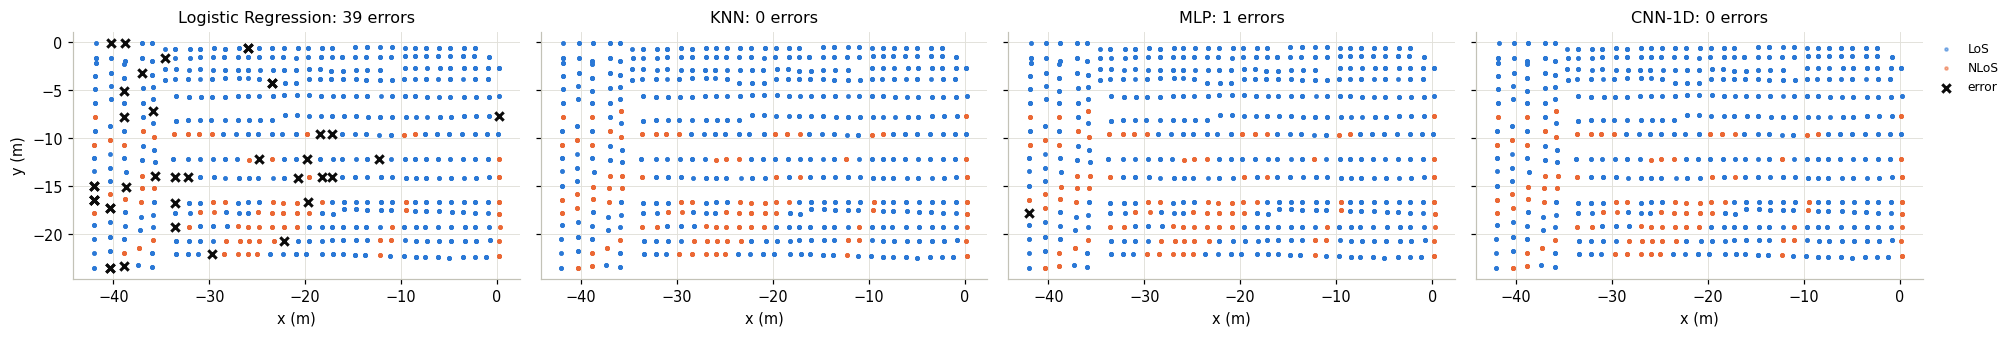

In [39]:
# Figure: misclassified validation samples on the map
fig, axes = plt.subplots(1, len(shown), figsize=(4.6 * len(shown), 2.9), sharey=True)
for ax, (name, pred) in zip(axes, shown.items()):
    wrong = pred != y_valid
    for c, cname in enumerate(CLASSES):
        m = y_valid == c
        ax.scatter(pos_valid[m, 0], pos_valid[m, 1], s=4, color=COLORS[cname], alpha=0.5, label=cname)
    ax.scatter(pos_valid[wrong, 0], pos_valid[wrong, 1], marker='x', s=30, color='#0b0b0b', label='error')
    ax.set(title=f'{name}: {wrong.sum()} errors', xlabel='x (m)')
    ax.set_aspect('equal')
axes[0].set_ylabel('y (m)')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
plt.show()

# Part D — Extra studies
## 8. Robustness on an emulated unreliable network
The models are trained on clean CSI and tested, **without retraining**, on corrupted copies of the validation CSI:
- **noisy CSI**: complex white Gaussian noise at a per-sample SNR of 30 … 0 dB;
- **lost CSI packets**: the 1632 subcarriers travel in 16 packets of 102 subcarriers (all 4 antennas); each packet
  is lost with probability *p* and the missing values are zero;
- **lost packets + repair** (receiver-side defence): the receiver knows which packets are missing. The CSI is
  de-rotated by the delay of the strongest path (so it varies slowly over frequency), the missing subcarriers are
  linearly interpolated from the received ones, and the rotation is applied again.

The corruption is applied to the complex CSI, and all inputs (amplitude, CIR, physical features) are then computed by
`preprocess`, so every model faces the same physical problem.

A second defence is **data augmentation**: a CNN-1D is trained on corrupted training CSI generated on the fly
(with probability 0.5 noise at a random SNR of 0–30 dB, with probability 0.5 a random packet-loss rate of 0–50 %).

In [40]:
N_PACKETS = 16


def add_awgn(H, snr_db, generator=None):
    """Complex white Gaussian noise; the SNR (dB, scalar or one value per sample) uses the mean |H|^2 of each sample."""
    power = H.abs().pow(2).mean(dim=(-2, -1), keepdim=True)
    snr = torch.as_tensor(snr_db, dtype=torch.float32, device=H.device)
    std = torch.sqrt(power / (2 * 10 ** (snr / 10)))
    noise = torch.view_as_complex(torch.randn(*H.shape, 2, generator=generator, device=H.device))
    return H + std * noise


def packet_mask(n, rate, generator=None, device='cpu'):
    """True = subcarrier lost. Each packet of 102 subcarriers is lost with probability `rate`."""
    lost = torch.rand(n, N_PACKETS, generator=generator, device=device) < rate
    return lost.repeat_interleave(1632 // N_PACKETS, dim=1)


def drop_packets(H, mask):
    return H * (~mask)[:, None, :]


def repair_packets(H, mask):
    """Interpolate the lost subcarriers of the CSI after removing the phase slope of the strongest path."""
    n_sc = H.shape[-1]
    k = torch.arange(n_sc)
    delay = torch.fft.ifft(H, dim=-1).abs().pow(2).sum(1).argmax(-1)
    rot = torch.exp(2j * np.pi * k[None, :] * delay[:, None] / n_sc).to(torch.complex64)
    Hd = (H * rot[:, None, :]).numpy()
    m, kk = mask.numpy(), np.arange(n_sc)
    for i in np.flatnonzero(m.any(1) & ~m.all(1)):
        lost, ok = m[i], ~m[i]
        for a in range(Hd.shape[1]):
            Hd[i, a, lost] = (np.interp(kk[lost], kk[ok], Hd[i, a, ok].real) +
                              1j * np.interp(kk[lost], kk[ok], Hd[i, a, ok].imag))
    return torch.from_numpy(Hd) * rot.conj()[:, None, :]


def amp_input(H, nrm):
    """complex CSI -> normalized amplitude input, exactly as in `preprocess` (works on the GPU)."""
    return (F.avg_pool1d(H.abs(), POOL) - nrm.amp_min) / (nrm.amp_max - nrm.amp_min)


def make_augment(nrm):
    """On-the-fly corruption of a training batch, scaled with the statistics `nrm` of the training data."""
    def augment(H):
        n, dev = len(H), H.device
        noisy = add_awgn(H, torch.empty(n, 1, 1, device=dev).uniform_(0, 30))
        H = torch.where(torch.rand(n, 1, 1, device=dev) < 0.5, noisy, H)
        mask = packet_mask(n, torch.empty(n, 1, device=dev).uniform_(0, 0.5), device=dev)
        mask &= torch.rand(n, 1, device=dev) < 0.5
        return (amp_input(drop_packets(H, mask), nrm),)
    return augment

In [41]:
set_seed()
aug_model = make_cnn1d(2)
aug_hist, aug_train_s = train_net(aug_model, (train_CSI,), y_train, (valid_gpu['amp'],), y_valid, transform=make_augment(norm))
aug_prob = nlos_prob(aug_model, (valid_gpu['amp'],))
print(f'CNN-1D + augmentation: clean validation accuracy {accuracy_score(y_valid, (aug_prob > 0.5).astype(int)):.4f}, '
      f'best epoch {aug_hist.attrs["best_epoch"]}, training {aug_train_s:.1f} s')

CNN-1D + augmentation: clean validation accuracy 1.0000, best epoch 25, training 49.5 s


In [42]:
ROBUST_ANN = {name: (ann_models[name], ARCHS[name][0]) for name in ['MLP', 'CNN-1D', 'CNN-2D', 'ResNet-1D', 'CIR-CNN', 'Fusion CNN']}
ROBUST_ANN['CNN-1D + augmentation'] = (aug_model, ('amp',))


def predict_label(name, inputs):
    if name in final_ml:
        fs, model = final_ml[name]
        return model.predict(ml_matrix(inputs, fs))
    model, keys = ROBUST_ANN[name]
    return (nlos_prob(model, tuple(inputs[k].to(device) for k in keys)) > 0.5).astype(int)


SNRS, LOSS_RATES = [30, 20, 10, 5, 0], [0.1, 0.2, 0.3, 0.5]
robust_names = list(final_ml) + list(ROBUST_ANN)
generator = torch.Generator().manual_seed(SEED)
rows = [{'corruption': 'clean', 'level': 0, 'model': n, 'accuracy': accuracy_score(y_valid, predict_label(n, valid_in))}
        for n in robust_names]
t0 = time.time()
for snr in SNRS:
    inputs = preprocess(add_awgn(valid_CSI, snr, generator))
    rows += [{'corruption': 'noise', 'level': snr, 'model': n, 'accuracy': accuracy_score(y_valid, predict_label(n, inputs))}
             for n in robust_names]
for rate in LOSS_RATES:
    mask = packet_mask(len(valid_CSI), rate, generator)
    lossy = drop_packets(valid_CSI, mask)
    for corruption, H in [('packet loss', lossy), ('packet loss + repair', repair_packets(lossy, mask))]:
        inputs = preprocess(H)
        rows += [{'corruption': corruption, 'level': rate, 'model': n,
                  'accuracy': accuracy_score(y_valid, predict_label(n, inputs))} for n in robust_names]
robust = pd.DataFrame(rows)
print(f'robustness test: {time.time() - t0:.1f} s')
clean_acc = robust[robust['corruption'] == 'clean'].set_index('model')['accuracy']


def pivot(corruption):
    r = robust[robust['corruption'] == corruption]
    return r.pivot(index='model', columns='level', values='accuracy').loc[robust_names]


def curve(corruption, name):
    r = robust[(robust['corruption'] == corruption) & (robust['model'] == name)]
    return r['level'].tolist(), r['accuracy'].tolist()


noise_table = pivot('noise')[SNRS].rename(columns=lambda s: f'{s:g} dB')
noise_table.insert(0, 'clean', clean_acc)
noise_table.round(4)

robustness test: 19.1 s


level,clean,30 dB,20 dB,10 dB,5 dB,0 dB
model,,,,,,
Logistic Regression,0.9922,0.9918,0.9796,0.8908,0.8264,0.8074
SVM (RBF),0.9998,0.9998,0.9998,0.9990,0.9800,0.8810
KNN,1.0000,1.0000,1.0000,1.0000,1.0000,0.8624
Random Forest,0.9986,0.9976,0.9896,0.9372,0.8548,0.4524
Gradient Boosting,0.9992,0.9990,0.9912,0.9230,0.7944,0.6870
MLP,0.9998,0.9998,0.9998,0.9982,0.9324,0.7260
CNN-1D,1.0000,1.0000,1.0000,0.9992,0.9592,0.8202
CNN-2D,1.0000,1.0000,1.0000,0.9954,0.9256,0.8194
ResNet-1D,1.0000,1.0000,1.0000,0.9962,0.9316,0.8294


In [43]:
loss_table = pd.concat({c: pivot(c)[LOSS_RATES] for c in ['packet loss', 'packet loss + repair']}, axis=1)
loss_table.insert(0, ('clean', 0), clean_acc)
loss_table.round(4)

clean packet loss                          \
level                     0.0         0.1     0.2     0.3     0.5   
model                                                               
Logistic Regression    0.9922      0.8446  0.8164  0.8136  0.8128   
SVM (RBF)              0.9998      0.8784  0.8350  0.8072  0.7826   
KNN                    1.0000      0.9796  0.9308  0.8588  0.7052   
Random Forest          0.9986      0.9148  0.8758  0.8592  0.8188   
Gradient Boosting      0.9992      0.9162  0.8728  0.8522  0.7960   
MLP                    0.9998      0.8964  0.8336  0.8068  0.7640   
CNN-1D                 1.0000      0.9300  0.8298  0.7118  0.5760   
CNN-2D                 1.0000      0.9272  0.8162  0.6928  0.5394   
ResNet-1D              1.0000      0.8910  0.7226  0.5544  0.3908   
CIR-CNN                0.9980      0.9406  0.8858  0.8308  0.7034   
Fusion CNN             1.0000      0.9470  0.8518  0.7472  0.6144   
CNN-1D + augmentation  1.0000      0.9998  0.9994  0.9976  0.9844   

                      packet loss + repair                          
level                                  0.1     0.2     0.3     0.5  
model                                                               
Logistic Regression                 0.9728  0.9452  0.9240  0.8712  
SVM (RBF)                           0.9886  0.9642  0.9340  0.8562  
KNN                                 1.0000  0.9994  0.9978  0.9800  
Random Forest                       0.9908  0.9774  0.9558  0.9114  
Gradient Boosting                   0.9894  0.9746  0.9536  0.9072  
MLP                                 0.9880  0.9680  0.9476  0.8958  
CNN-1D                              0.9980  0.9926  0.9816  0.9360  
CNN-2D                              0.9966  0.9916  0.9796  0.9300  
ResNet-1D                           0.9990  0.9924  0.9774  0.9268  
CIR-CNN                             0.9958  0.9842  0.9728  0.9326  
Fusion CNN                          0.9984  0.9950  0.9864  0.9546  
CNN-1D + augmentation               0.9988  0.9950  0.9842  0.9404

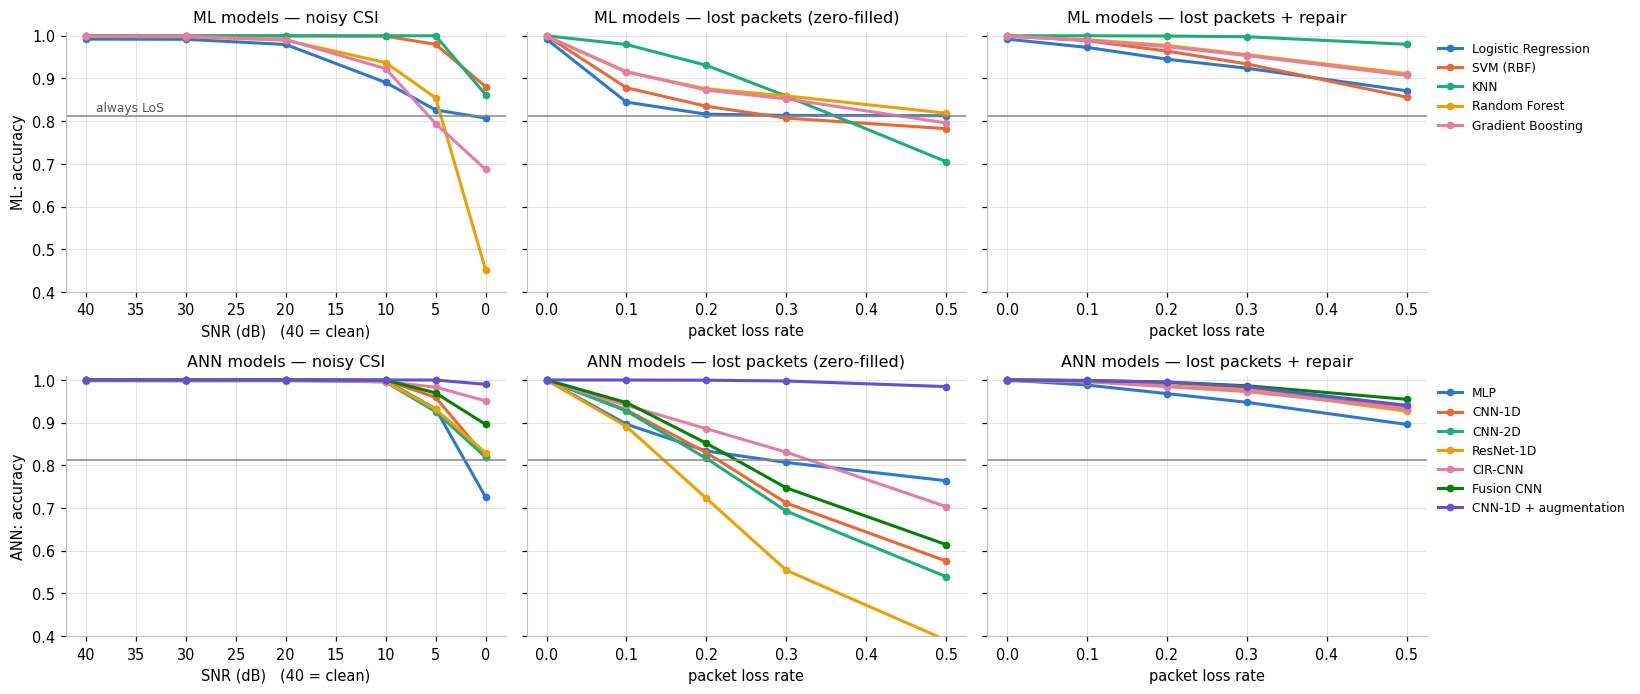

In [44]:
# Figure: robustness to noise and packet loss
fig, axes = plt.subplots(2, 3, figsize=(15, 6.4), sharey='row')
groups = [('ML', list(final_ml)), ('ANN', list(ROBUST_ANN))]
for row, (kind, names) in enumerate(groups):
    for i, name in enumerate(names):
        level, acc = curve('noise', name)
        axes[row, 0].plot([40] + level, [clean_acc[name]] + acc, marker='o', ms=4, color=PALETTE[i], label=name)
        for col, corruption in [(1, 'packet loss'), (2, 'packet loss + repair')]:
            level, acc = curve(corruption, name)
            axes[row, col].plot([0] + level, [clean_acc[name]] + acc, marker='o', ms=4, color=PALETTE[i], label=name)
    axes[row, 0].set(xlabel='SNR (dB)   (40 = clean)', ylabel=f'{kind}: accuracy', title=f'{kind} models — noisy CSI')
    axes[row, 0].invert_xaxis()
    axes[row, 1].set(xlabel='packet loss rate', title=f'{kind} models — lost packets (zero-filled)')
    axes[row, 2].set(xlabel='packet loss rate', title=f'{kind} models — lost packets + repair')
    axes[row, 2].legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=8)
    for ax in axes[row]:
        ax.axhline(np.mean(y_valid == 0), color='#898781', lw=1)
        ax.set_ylim(0.4, 1.01)
axes[0, 0].text(39, np.mean(y_valid == 0) + 0.01, 'always LoS', fontsize=8, color='#52514e')
plt.tight_layout()
plt.show()

## 9. Generalization to positions never seen in training
The official training and validation sets contain the **same 476 positions** (about 32 training and 11 validation
samples per position), so a model can reach a high validation score by recognising the fingerprint of a known
position. To measure generalization, all 20,000 samples are split **by position** (`GroupShuffleSplit`): the samples
of 80 % of the positions are used for training and those of the other 20 % — positions never seen in training — for
testing. The final configurations of Sections 4 and 6 are trained again on the seen positions only:
- all scaling statistics (min-max, PCA, standardization) are recomputed from the **seen** positions;
- early stopping of the networks uses an **inner validation split** (15 % of the seen positions); the unseen test
  positions are used only once, for the final evaluation.

In [45]:
all_phys = np.vstack([train_in['phys'], valid_in['phys']])
y_all = np.concatenate([y_train, y_valid])
pos_all = np.vstack([pos_train, pos_valid])
position_id = np.unique(pos_all, axis=0, return_inverse=True)[1].reshape(-1)
seen, unseen = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(pos_all, groups=position_id))
assert not set(position_id[seen]) & set(position_id[unseen])        # no position in both parts
seen_t, unseen_t = torch.from_numpy(seen), torch.from_numpy(unseen)
norm_seen = Normalizer(RAW['amp'][seen_t], RAW['cir'][seen_t])        # statistics of the seen positions only
seen_in = {**norm_seen(RAW['amp'][seen_t], RAW['cir'][seen_t]), 'phys': all_phys[seen]}
unseen_in = {**norm_seen(RAW['amp'][unseen_t], RAW['cir'][unseen_t]), 'phys': all_phys[unseen]}
y_seen, y_unseen = y_all[seen], y_all[unseen]
fit_part, stop_part = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(seen, groups=position_id[seen]))
print(f'positions: {position_id.max() + 1} | seen {len(np.unique(position_id[seen]))} '
      f'(network training {len(np.unique(position_id[seen][fit_part]))}, early stopping {len(np.unique(position_id[seen][stop_part]))}) '
      f'| unseen {len(np.unique(position_id[unseen]))}')
print(f'samples  : seen {len(seen)} | unseen {len(unseen)} | NLoS share of the unseen samples {y_unseen.mean():.3f}')
print(f'scaling statistics from the seen positions: |H| in [{norm_seen.amp_min:.1f}, {norm_seen.amp_max:.1f}]')

positions: 476 | seen 380 (network training 323, early stopping 57) | unseen 96
samples  : seen 15919 | unseen 4081 | NLoS share of the unseen samples 0.212
scaling statistics from the seen positions: |H| in [1.9, 2825.0]


In [46]:
unseen_pred, unseen_score, unseen_rows = {}, {}, []
for name, (fs, model) in final_ml.items():
    r, unseen_pred[name], unseen_score[name] = fit_ml(clone(model), ml_matrix(seen_in, fs), y_seen,
                                                      ml_matrix(unseen_in, fs), y_unseen)
    unseen_rows.append({'model': name, 'type': 'ML', **{k: r[k] for k in ['accuracy', 'precision', 'recall', 'F1', 'AUC', 'train_s']}})
fit_t, stop_t = torch.as_tensor(fit_part, device=device), torch.as_tensor(stop_part, device=device)
seen_gpu = {k: seen_in[k].to(device) for k in ['amp', 'cir']}
unseen_gpu = {k: unseen_in[k].to(device) for k in ['amp', 'cir']}
fit_CSI = torch.cat([train_CSI, valid_CSI.to(device)])[torch.as_tensor(seen, device=device)][fit_t]
for name in list(ROBUST_ANN):
    set_seed()
    if name == 'CNN-1D + augmentation':
        model, keys = make_cnn1d(2), ('amp',)
        hist, train_s = train_net(model, (fit_CSI,), y_seen[fit_part], (seen_gpu['amp'][stop_t],), y_seen[stop_part],
                                  transform=make_augment(norm_seen))
    else:
        keys, build = ARCHS[name]
        model = build(2)
        hist, train_s = train_net(model, tuple(seen_gpu[k][fit_t] for k in keys), y_seen[fit_part],
                                  tuple(seen_gpu[k][stop_t] for k in keys), y_seen[stop_part])
    prob = nlos_prob(model, tuple(unseen_gpu[k] for k in keys))
    unseen_pred[name], unseen_score[name] = (prob > 0.5).astype(int), prob
    unseen_rows.append({'model': name, 'type': 'ANN', **cls_metrics(y_unseen, unseen_pred[name], prob), 'train_s': train_s,
                        'best_epoch': hist.attrs['best_epoch']})
del fit_CSI
unseen_table = pd.DataFrame(unseen_rows).set_index('model')
print('always predicting LoS: accuracy %.4f' % np.mean(y_unseen == 0))
unseen_table.round(4)

always predicting LoS: accuracy 0.7878


,type,accuracy,precision,recall,F1,AUC,train_s,best_epoch
model,,,,,,,,
Logistic Regression,ML,0.7613,0.4015,0.2540,0.3112,0.7575,2.7187,NaN
SVM (RBF),ML,0.7650,0.3991,0.2125,0.2773,0.7115,1.8768,NaN
KNN,ML,0.7650,0.0957,0.0127,0.0224,0.4902,1.0275,NaN
Random Forest,ML,0.8486,0.9429,0.3048,0.4607,0.8449,1.0875,NaN
Gradient Boosting,ML,0.8260,0.7600,0.2633,0.3911,0.8033,0.4463,NaN
MLP,ANN,0.7841,0.3913,0.0312,0.0578,0.5365,2.6079,1.0
CNN-1D,ANN,0.7207,0.3913,0.5693,0.4638,0.6965,6.5597,1.0
CNN-2D,ANN,0.8047,0.5652,0.3453,0.4287,0.7300,5.6874,1.0
ResNet-1D,ANN,0.8179,0.6003,0.4249,0.4976,0.7213,17.8297,2.0


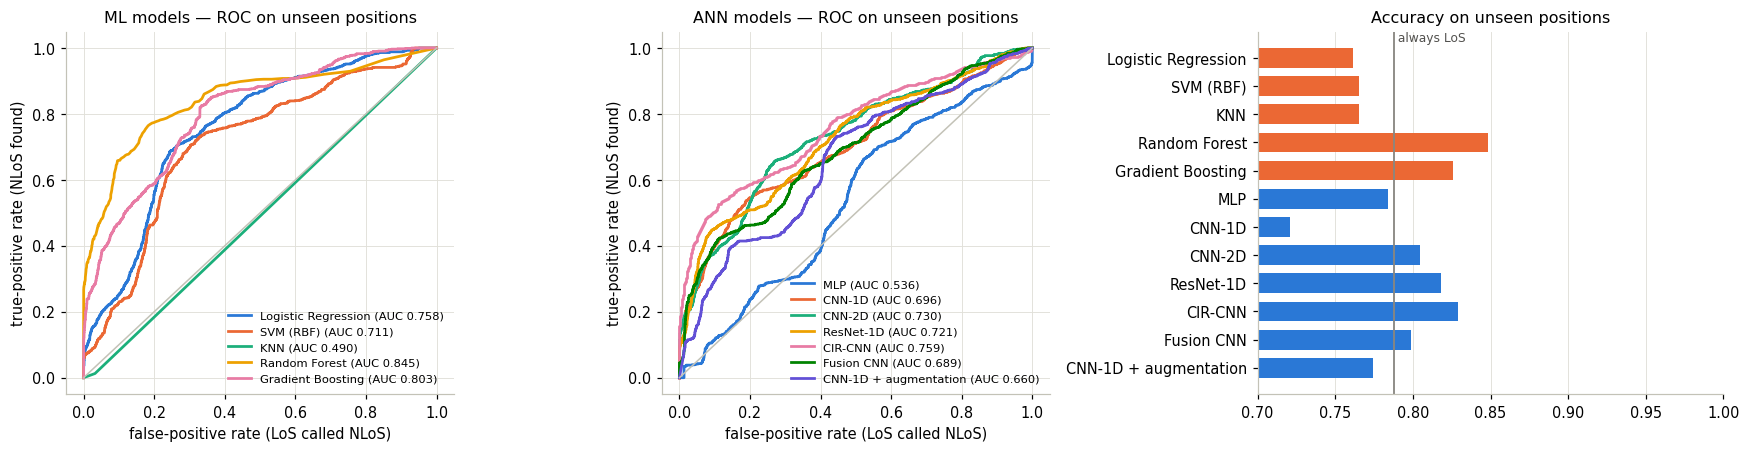

In [47]:
# Figure: unseen positions - ROC curves and accuracy
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={'width_ratios': [1, 1, 1.2]})
for ax, (kind, names) in zip(axes[:2], groups):
    for i, name in enumerate(names):
        fpr, tpr, _ = roc_curve(y_unseen, unseen_score[name])
        ax.plot(fpr, tpr, lw=1.8, color=PALETTE[i], label=f'{name} (AUC {unseen_table.loc[name, "AUC"]:.3f})')
    ax.plot([0, 1], [0, 1], color='#c3c2b7', lw=1)
    ax.set(title=f'{kind} models — ROC on unseen positions', xlabel='false-positive rate (LoS called NLoS)',
           ylabel='true-positive rate (NLoS found)')
    ax.legend(fontsize=7.5, loc='lower right')
order = unseen_table.index[::-1]
axes[2].barh(range(len(order)), unseen_table.loc[order, 'accuracy'], color=[COLORS[t] for t in unseen_table.loc[order, 'type']], height=0.7)
axes[2].axvline(np.mean(y_unseen == 0), color='#898781', lw=1.2)
axes[2].text(np.mean(y_unseen == 0), len(order) - 0.4, ' always LoS', fontsize=8, color='#52514e')
axes[2].set(yticks=range(len(order)), yticklabels=order, xlim=(0.7, 1.0), title='Accuracy on unseen positions')
axes[2].grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

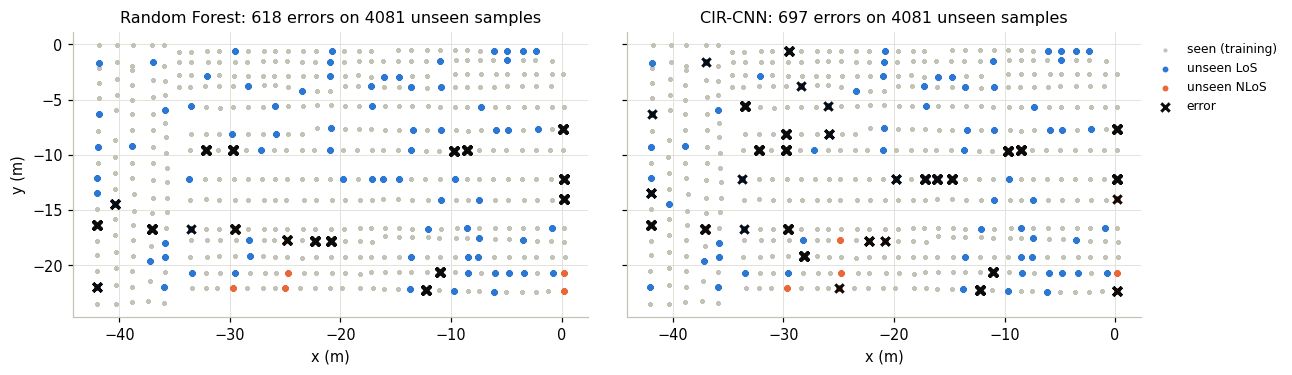

In [48]:
# Figure: errors on unseen positions
best_ml_unseen = unseen_table[unseen_table['type'] == 'ML']['F1'].idxmax()
best_ann_unseen = unseen_table[unseen_table['type'] == 'ANN']['F1'].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3), sharey=True)
for ax, name in zip(axes, [best_ml_unseen, best_ann_unseen]):
    wrong = unseen_pred[name] != y_unseen
    ax.scatter(pos_all[seen, 0], pos_all[seen, 1], s=3, color='#c3c2b7', label='seen (training)')
    for c, cname in enumerate(CLASSES):
        m = y_unseen == c
        ax.scatter(pos_all[unseen][m, 0], pos_all[unseen][m, 1], s=8, color=COLORS[cname], label=f'unseen {cname}')
    ax.scatter(pos_all[unseen][wrong, 0], pos_all[unseen][wrong, 1], marker='x', s=30, color='#0b0b0b', label='error')
    ax.set(title=f'{name}: {wrong.sum()} errors on {len(unseen)} unseen samples', xlabel='x (m)')
    ax.set_aspect('equal')
axes[0].set_ylabel('y (m)')
axes[1].legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
plt.show()

## 10. Summary of the key results
Final comparison on the official validation set (known positions) and accuracy on the unseen positions.

In [49]:
final_table = summary[['type', 'accuracy', 'F1', 'AUC', 'best_epoch', 'train_s', 'cpu_latency_ms', 'size_MB']].join(
    unseen_table[['accuracy']].rename(columns={'accuracy': 'unseen_acc'})).round(4)
final_table

,type,accuracy,F1,AUC,best_epoch,train_s,cpu_latency_ms,size_MB,unseen_acc
model,,,,,,,,,
Logistic Regression,ML,0.9922,0.9791,0.9987,<NA>,3.9756,0.5084,0.0387,0.7613
SVM (RBF),ML,0.9998,0.9995,1.0000,<NA>,2.6224,0.3494,1.0957,0.7650
KNN,ML,1.0000,1.0000,1.0000,<NA>,1.3918,1.7482,6.7819,0.7650
Random Forest,ML,0.9986,0.9962,1.0000,<NA>,1.9363,6.1562,14.0342,0.8486
Gradient Boosting,ML,0.9992,0.9979,0.9998,<NA>,0.5664,1.7551,0.3365,0.8260
MLP,ANN,0.9998,0.9995,1.0000,23,32.6246,0.3125,3.8746,0.7841
CNN-1D,ANN,1.0000,1.0000,1.0000,25,59.0470,1.2437,0.6810,0.7207
CNN-2D,ANN,1.0000,1.0000,1.0000,24,55.4111,2.4601,0.4044,0.8047
ResNet-1D,ANN,1.0000,1.0000,1.0000,25,85.5492,1.3186,0.9382,0.8179


In [50]:
key = {'validation (known positions)': summary[['type', 'accuracy', 'F1', 'AUC', 'train_s', 'cpu_latency_ms', 'size_MB', 'params', 'best_epoch']].round(5).to_dict('index'),
       'training': {'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'checkpoint': ckpt_name,
                    'augmented_best_epoch': aug_hist.attrs['best_epoch']},
       'unseen positions': unseen_table[['accuracy', 'F1', 'AUC']].round(4).to_dict('index'),
       'noise accuracy': noise_table.round(4).to_dict('index'),
       'packet loss accuracy': {m: {f'{c} {l}': v for (c, l), v in row.items()} for m, row in loss_table.round(4).to_dict('index').items()},
       'best ML': best_ml, 'best ANN': best_ann, 'best unseen': [best_ml_unseen, best_ann_unseen]}
print(json.dumps(key, indent=1, default=str))

{
 "validation (known positions)": {
  "Logistic Regression": {
   "type": "ML",
   "accuracy": 0.9922,
   "F1": 0.97911,
   "AUC": 0.99871,
   "train_s": 3.97559,
   "cpu_latency_ms": 0.50835,
   "size_MB": 0.03871,
   "params": null,
   "best_epoch": null
  },
  "SVM (RBF)": {
   "type": "ML",
   "accuracy": 0.9998,
   "F1": 0.99947,
   "AUC": 1.0,
   "train_s": 2.62237,
   "cpu_latency_ms": 0.3494,
   "size_MB": 1.09567,
   "params": null,
   "best_epoch": null
  },
  "KNN": {
   "type": "ML",
   "accuracy": 1.0,
   "F1": 1.0,
   "AUC": 1.0,
   "train_s": 1.39176,
   "cpu_latency_ms": 1.7482,
   "size_MB": 6.78192,
   "params": null,
   "best_epoch": null
  },
  "Random Forest": {
   "type": "ML",
   "accuracy": 0.9986,
   "F1": 0.99625,
   "AUC": 0.99998,
   "train_s": 1.93631,
   "cpu_latency_ms": 6.1562,
   "size_MB": 14.0342,
   "params": null,
   "best_epoch": null
  },
  "Gradient Boosting": {
   "type": "ML",
   "accuracy": 0.9992,
   "F1": 0.99786,
   "AUC": 0.99983,
   "tra

## 11. Compact figures for the report
The main results drawn again at the size of an IEEE column (3.45 in) or page (7.1 in) with 8-pt text.
ML models are drawn with dashed lines and ANN models with solid lines.

In [51]:
REPORT_RC = {'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'], 'mathtext.fontset': 'stix',
             'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
             'legend.fontsize': 7, 'lines.linewidth': 1.3, 'lines.markersize': 3, 'figure.dpi': 220}
COL, PAGE = 3.45, 7.1
REPORT_MODELS = ['Logistic Regression', 'SVM (RBF)', 'KNN', 'Random Forest', 'Gradient Boosting',
                 'CNN-1D', 'ResNet-1D', 'CNN-1D + augmentation']
MODEL_STYLE = {name: dict(color=PALETTE[i], ls='--' if name in final_ml else '-') for i, name in enumerate(REPORT_MODELS)}

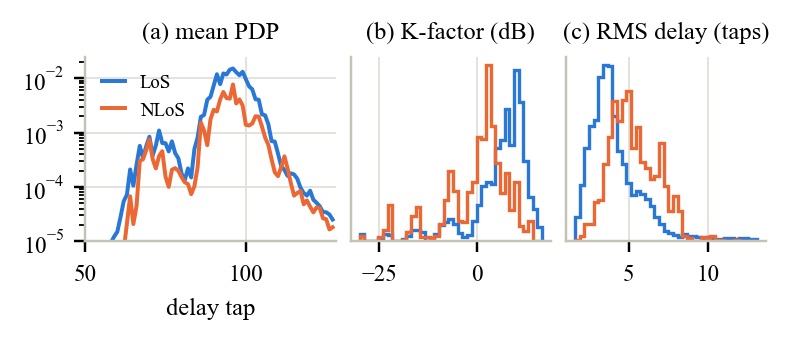

In [52]:
# Figure: report - LoS vs NLoS signatures
with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(1, 3, figsize=(COL, 1.42), gridspec_kw={'width_ratios': [1.25, 1, 1]})
    for c, name in enumerate(CLASSES):
        m = torch.from_numpy(y_train == c)
        axes[0].semilogy(train_in['cir'][m, 0].pow(2).mean(0), color=COLORS[name], label=name)
    axes[0].set(title='(a) mean PDP', xlabel='delay tap', xlim=(50, 128), ylim=(1e-5, None))
    axes[0].legend(loc='upper left', fontsize=6.2, handlelength=1.2)
    for ax, (feat, title) in zip(axes[1:], [('K_factor_dB', '(b) K-factor (dB)'), ('rms_delay', '(c) RMS delay (taps)')]):
        v = antenna_mean(feat)
        bins = np.linspace(np.percentile(v, 0.5), np.percentile(v, 99.5), 40)
        for c, name in enumerate(CLASSES):
            ax.hist(v[y_train == c], bins=bins, density=True, histtype='step', lw=1.1, color=COLORS[name])
        ax.set(title=title)
        ax.set_yticks([])
    plt.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.6)
    plt.show()

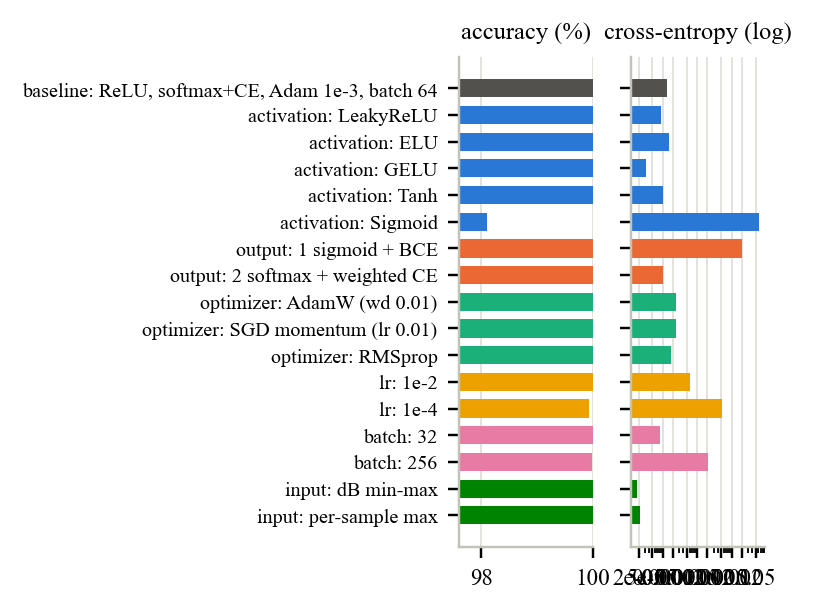

In [53]:
# Figure: report - configuration study
SHORT = {'Hidden activation': 'activation', 'Output layer / loss': 'output', 'Optimizer': 'optimizer',
         'Learning rate': 'lr', 'Batch size': 'batch', 'Input normalization': 'input'}
rows = config_table[~config_table['setting'].str.endswith('(baseline)')]
rows = pd.concat([pd.DataFrame([{**baseline, 'study': 'baseline', 'setting': 'ReLU, softmax+CE, Adam 1e-3, batch 64'}]), rows])
labels = ['baseline: ' + rows['setting'].iloc[0]] + [f'{SHORT[s]}: {t}' for s, t in zip(rows['study'][1:], rows['setting'][1:])]
colors = ['#52514e'] + [PALETTE[list(STUDIES).index(s)] for s in rows['study'][1:]]
with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(1, 2, figsize=(COL, 2.65), sharey=True, gridspec_kw={'width_ratios': [1, 1]})
    ypos = np.arange(len(rows))[::-1]
    axes[0].barh(ypos, 100 * rows['accuracy'], color=colors, height=0.68)
    axes[0].set(xlim=(max(50, 100 * rows['accuracy'].min() - 0.5), 100), title='accuracy (%)', yticks=ypos, yticklabels=labels)
    axes[1].barh(ypos, rows['val_loss'], color=colors, height=0.68)
    log_axis(axes[1])
    axes[1].set(title='cross-entropy (log)')
    for ax in axes:
        ax.grid(axis='y', visible=False)
        ax.tick_params(axis='y', labelsize=6.6)
    plt.tight_layout(pad=0.3, w_pad=0.4)
    plt.show()

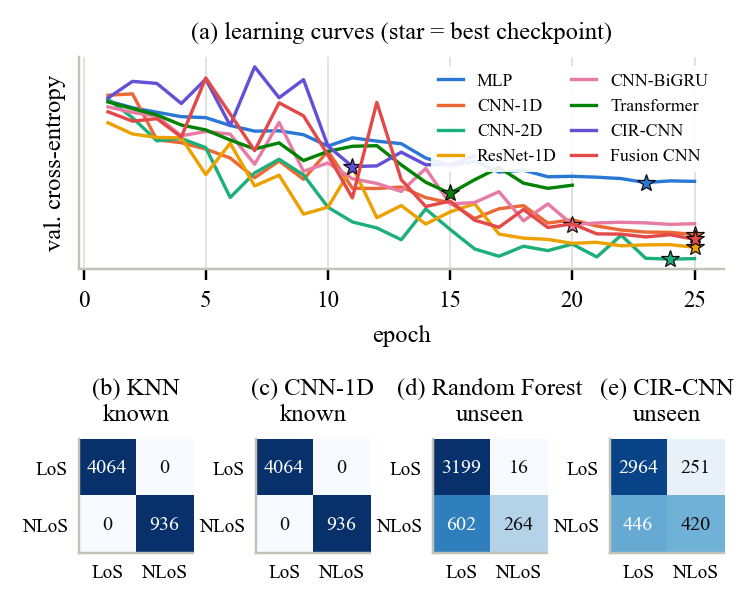

In [54]:
# Figure: report - learning curves and confusion matrices
def small_cm(ax, true, pred, title):
    cm = confusion_matrix(true, pred, labels=[0, 1])
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
    for (r, c), v in np.ndenumerate(cm):
        ax.text(c, r, f'{v}', ha='center', va='center', fontsize=6.6, color='white' if cm[r, c] / cm[r].sum() > 0.5 else '#0b0b0b')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=CLASSES, yticklabels=CLASSES, title=title)
    ax.tick_params(labelsize=6.3, length=0)
    ax.grid(False)


with plt.rc_context(REPORT_RC):
    fig = plt.figure(figsize=(COL, 2.8))
    gs = fig.add_gridspec(2, 4, height_ratios=[1.25, 1], hspace=0.75, wspace=0.55)
    ax = fig.add_subplot(gs[0, :])
    for i, (name, hist) in enumerate(ann_hist.items()):
        ax.plot(hist['epoch'], hist['val_loss'], color=PALETTE[i], lw=1.1, label=name)
        b = hist.attrs['best_epoch']
        ax.plot(b, hist.loc[b - 1, 'val_loss'], marker='*', ms=6, color=PALETTE[i], markeredgecolor='#0b0b0b', markeredgewidth=0.4)
    log_axis(ax, 'y')
    ax.set(xlabel='epoch', ylabel='val. cross-entropy', title='(a) learning curves (star = best checkpoint)')
    ax.legend(ncol=2, fontsize=5.8, loc='upper right', handlelength=1.4, columnspacing=0.8, frameon=True, framealpha=0.9, edgecolor='none')
    panels = [(y_valid, ml_pred[best_ml], f'(b) {best_ml}\nknown'),
              (y_valid, (ann_prob[best_ann] > 0.5).astype(int), f'(c) {best_ann}\nknown'),
              (y_unseen, unseen_pred[best_ml_unseen], f'(d) {best_ml_unseen}\nunseen'),
              (y_unseen, unseen_pred[best_ann_unseen], f'(e) {best_ann_unseen}\nunseen')]
    for k, (true, pred, title) in enumerate(panels):
        small_cm(fig.add_subplot(gs[1, k]), true, pred, title)
    plt.subplots_adjust(left=0.13, right=0.98, top=0.93, bottom=0.08)
    plt.show()

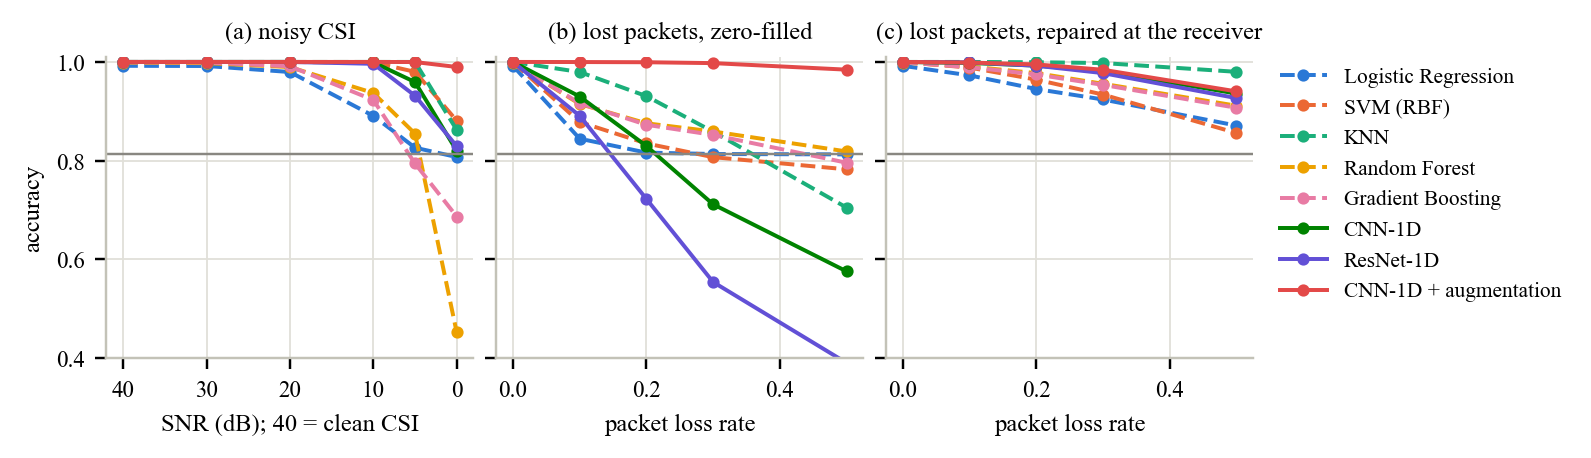

In [55]:
# Figure: report - robustness
with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(1, 3, figsize=(PAGE, 1.95), sharey=True)
    for name in REPORT_MODELS:
        level, acc = curve('noise', name)
        axes[0].plot([40] + level, [clean_acc[name]] + acc, marker='o', label=name, **MODEL_STYLE[name])
        for ax, corruption in [(axes[1], 'packet loss'), (axes[2], 'packet loss + repair')]:
            level, acc = curve(corruption, name)
            ax.plot([0] + level, [clean_acc[name]] + acc, marker='o', label=name, **MODEL_STYLE[name])
    axes[0].set(xlabel='SNR (dB); 40 = clean CSI', ylabel='accuracy', title='(a) noisy CSI')
    axes[0].invert_xaxis()
    axes[1].set(xlabel='packet loss rate', title='(b) lost packets, zero-filled')
    axes[2].set(xlabel='packet loss rate', title='(c) lost packets, repaired at the receiver')
    for ax in axes:
        ax.axhline(np.mean(y_valid == 0), color='#898781', lw=0.8)
        ax.set_ylim(0.4, 1.01)
    axes[2].legend(loc='upper left', bbox_to_anchor=(1.02, 1.03), handlelength=2.2)
    plt.tight_layout(pad=0.3, w_pad=0.5)
    plt.show()

## 12. Conclusions

1. **Input design.** The amplitude image (PCA features for ML), the CIR and the 46 physical features all separate LoS from
   NLoS; LoS samples have a larger Rician K-factor, a smaller delay spread and a stronger dominant tap (Section 2).
   A linear model needs non-linear (polynomial) features to reach F1 = 0.979.
2. **Known positions (official validation set).** ML: KNN classify every sample correctly; ANN:
   5 of 8 networks (CNN-1D, CNN-2D, ResNet-1D, CNN-BiGRU, Fusion CNN) reach 100 %; with early stopping (at most
   25 epochs, patience 5) their best checkpoints are at epochs
   11-25. The task is easy on
   known positions because every validation sample has near-identical training samples from the same position.
3. **Configurations.** Sigmoid hidden units and a learning rate of 1e-4 are clearly worse; GELU and per-sample input
   scaling converge fastest; a single sigmoid output is as accurate as softmax but less confident (Section 6.2).
4. **Efficiency.** Gradient Boosting and KNN are the fastest ML models to train;
   the CNNs are small (0.40-0.94 MB) with single-sample
   CPU latencies of 0.66-2.46 ms; KNN (6.8 MB) and Random Forest
   (14.0 MB) are the largest models (Section 7.1).
5. **Unreliable network.** Clean-trained models lose accuracy with noise and lost packets; the receiver-side repair
   restores most of it, and noise/packet-loss augmentation keeps the CNN-1D at 99.0 % (0 dB) and
   98.4 % (50 % loss) (Section 8).
6. **Unseen positions.** All models drop close to the always-LoS baseline; the best accuracy is
   84.9 % (Random Forest) and the best NLoS F1 only 0.55 (Section 9).
   Generalization to new positions, not accuracy on known positions, is the real challenge of this dataset.
7. **Limitations.** The validation set shares its positions with the training set and is also used for model selection
   and early stopping, so its scores are optimistic; the unseen-position test is a single split with one seed.
